<a href="https://colab.research.google.com/github/jcartere-lgtm/PINN-PINO-Project-3/blob/main/ColabCode3PINN/PINO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Design Optimization Project 3: PINN/PINO**

Project purpose and approach

This project investigates neural methods for one-dimensional Bose–Einstein condensate control, inspired by Adriazola and Goodman’s squeezing problem.

We pursue Path B: Diagnosis. We compare a conventional Gross–Pitaevskii solver with a physics-informed space–time network and a matching data-only network. Time horizon is our difficulty knob. A supervised FNO provides a supplementary final-time surrogate experiment.

Our experiments investigate when predictions deteriorate and whether removing physics losses resolves the failure. We evaluate numerical consistency, prediction errors, loss components, and computational cost.

This Code is just to load tools we need


- NumPy: Handles mathematical calculations and arrays of numbers.
- SciPy: Helps solve optimization problems.
- Matplotlib: Creates graphs to visualize our results.
- PyTorch: Will be used later to build our AI model.
- Time: Helps us measure how long calculations take.
Why we're using it: These libraries provide the mathematical, visualization, and machine-learning tools needed to complete the project.

In [3]:
# @title
import numpy as np
import scipy
import matplotlib.pyplot as plt
import torch
import time

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("PyTorch:", torch.__version__)
print("Environment is ready!")

NumPy: 2.1.3
SciPy: 1.16.3
PyTorch: 2.11.0+cpu
Environment is ready!


This code simulates squeezing a Bose–Einstein condensate (BEC) wave packet using the Gross–Pitaevskii equation (GPE), which is the equation discussed in J. Adriazola and R. H. Goodman research paper.

First, the code creates a simulation area and generates a Gaussian wave packet as the starting point. It then applies a control that gradually increases from 1 to 100 over 2.5 units of time. This control strengthens a potential that confines the wave, causing it to become narrower.

The code uses the split-step Fourier method to calculate how the wave changes over 2,500 time steps. It accounts for the wave's movement, the external potential, and nonlinear interactions within the condensate.

Finally, it creates a graph comparing the initial and final wave shapes and checks that the total probability remains approximately 100%.

Why we're using it for our project: This is our first traditional numerical simulation of the researcher's wave-squeezing problem. It helps us understand how applying a control changes the wave before we attempt to optimize that control and compare the results against an AI neural operator.

In our simulation, the wave's width decreased by 52.56%, showing that the applied control successfully squeezed it. However, this is a starting simulation using a Gaussian initial wave, not yet an optimized solution that reproduces the paper's full experiment

### Mathematical formulation

We solve the dimensionless one-dimensional Gross–Pitaevskii equation:

$$
i\psi_t=-\frac12\psi_{xx}+\frac12u(t)x^2\psi+|\psi|^2\psi.
$$

The computational domain is $x\in[-8,8)$ with periodic boundary
conditions and 512 spatial points. The simulation uses
$\Delta t=0.001$ and final time $T=2.5$.

The initial state is $\psi(x,0)=C\exp(-x^2/2)$, normalized
numerically to unit probability. This Gaussian simplifies the
paper's initial condition, which uses a superposition of two
even modes selected through reduced-Hamiltonian minimization.

The baseline control is $u(t)=1+99t/T$. Optimized controls add
three sine terms:

$$
u(t)=1+99t/T+\sum_{n=1}^{3}a_n\sin(n\pi t/T).
$$

For the matched optimization comparison, coefficients satisfy
$a_n\in[-20,20]$. These coefficient bounds do not impose the
same bounds on the control itself.

Our difficulty knob is the observation/training horizon:
0.1, 0.5, 1.0, and 2.5. The control schedule remains unchanged;
each experiment uses a different-length prefix of the trajectory.

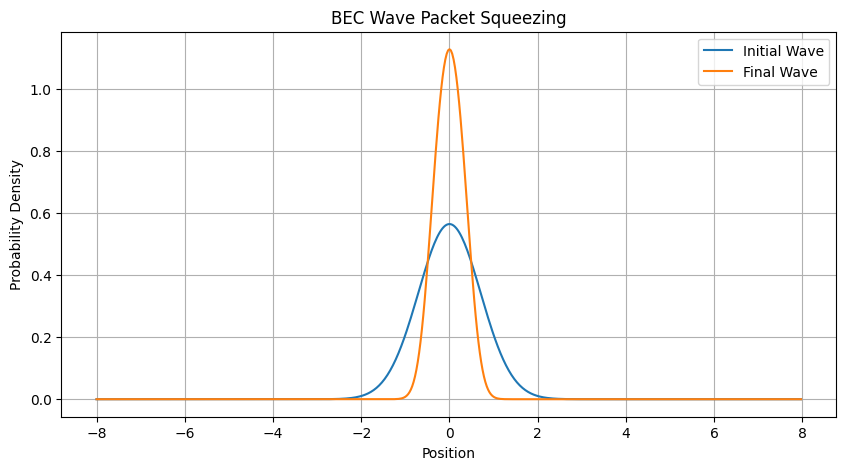

Final probability: 1.0000000000003375


In [36]:
# @title
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
N = 512
L = 16.0
dx = L / N
x = np.linspace(-L/2, L/2, N, endpoint=False)
k = 2 * np.pi * np.fft.fftfreq(N, d=dx)

# Time settings for our minimal case
T = 2.5
dt = 0.001
steps = int(T / dt)

# Starting and ending control values
u0 = 1.0
uT = 100.0

# Initial Gaussian wave packet
psi = np.exp(-x**2 / 2).astype(complex)

# Normalize wave function
psi /= np.sqrt(np.sum(np.abs(psi)**2) * dx)
psi_start = psi.copy()

initial_density = np.abs(psi)**2

# Store wave evolution for plotting
history = [initial_density.copy()]
times = [0.0]

# Split-step Fourier method
for step in range(steps):

    t_mid = (step + 0.5) * dt

    # Control from Equation 21
    u = u0 + (uT - u0) * t_mid / T

    # Quadratic potential
    V = 0.5 * u * x**2

    # First half-step: potential + nonlinear term
    psi *= np.exp(
        -0.5j * dt * (V + np.abs(psi)**2)
    )

    # Full kinetic step
    psi_k = np.fft.fft(psi)
    psi_k *= np.exp(-0.5j * k**2 * dt)
    psi = np.fft.ifft(psi_k)

    # Second half-step
    psi *= np.exp(
        -0.5j * dt * (V + np.abs(psi)**2)
    )

    # Save snapshots
    if (step + 1) % 25 == 0:
        history.append(np.abs(psi)**2)
        times.append((step + 1) * dt)

final_density = np.abs(psi)**2

# Compare starting and ending wave
plt.figure(figsize=(10, 5))
plt.plot(x, initial_density, label="Initial Wave")
plt.plot(x, final_density, label="Final Wave")
plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("BEC Wave Packet Squeezing")
plt.legend()
plt.grid(True)
plt.show()

# Check probability conservation
probability = np.sum(np.abs(psi)**2) * dx
print("Final probability:", probability)


In [9]:
# @title
initial_width = np.sqrt(
    np.sum(x**2 * initial_density) * dx
)

final_width = np.sqrt(
    np.sum(x**2 * final_density) * dx
)

reduction = (
    (initial_width - final_width) / initial_width
) * 100

print("Initial Width:", round(initial_width, 4))
print("Final Width:", round(final_width, 4))
print("Squeezing Percentage:", round(reduction, 2), "%")


Initial Width: 0.7071
Final Width: 0.3355
Squeezing Percentage: 52.56 %


This code saves the results from our traditional BEC wave-squeezing simulation into a CSV file called baseline_results.csv.

In [10]:
# @title
# Save our baseline simulation results

import pandas as pd

results = pd.DataFrame({
    "Measurement": [
        "Initial Width",
        "Final Width",
        "Squeezing Percentage",
        "Final Probability"
    ],
    "Value": [
        initial_width,
        final_width,
        reduction,
        probability
    ]
})

results.to_csv("baseline_results.csv", index=False)

print(results)
print("Results saved successfully!")

            Measurement      Value
0         Initial Width   0.707107
1           Final Width   0.335464
2  Squeezing Percentage  52.558214
3     Final Probability   1.000000
Results saved successfully!


**Origional Wave VS Stable Target Wave**

This code calculates a stable target wave for our Bose–Einstein condensate (BEC) using a mathematical technique called imaginary-time propagation.

First, it creates a Gaussian wave and applies the final control strength of 100. It then uses the split-step Fourier method with imaginary time to gradually move the wave toward a low-energy, stable state.

Once the calculation is finished, the code creates a graph comparing our original simulation against the stable target wave.

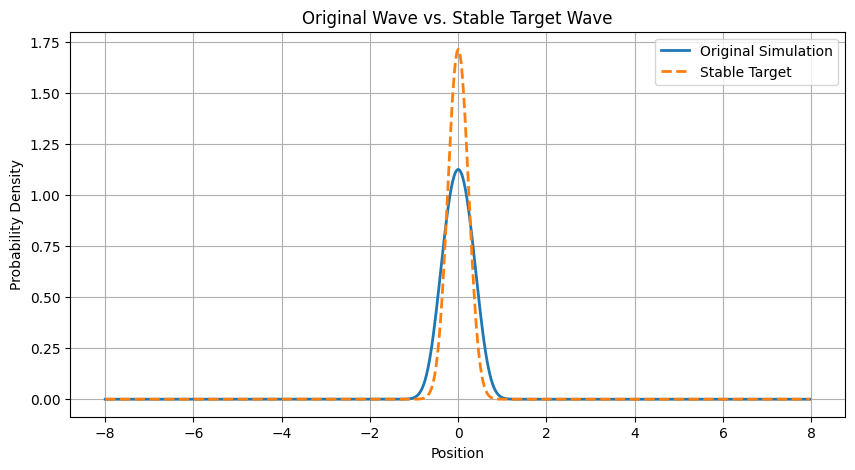

Stable target probability: 1.0
Target relative stationary residual: 0.00024064387906642669


In [37]:
# @title
# Step 1: Calculate a stable target wave

# Final potential strength
u_target = 100.0
V_target = 0.5 * u_target * x**2

# Start with a Gaussian wave
target_wave = np.exp(-x**2 / 2).astype(complex)
target_wave /= np.sqrt(np.sum(np.abs(target_wave)**2) * dx)

# Imaginary-time settings
imag_dt = 0.0005
imag_steps = 10000

for step in range(imag_steps):

    # First half-step: potential and nonlinear interaction
    target_wave *= np.exp(
        -0.5 * imag_dt * (V_target + np.abs(target_wave)**2)
    )

    # Kinetic step in Fourier space
    target_k = np.fft.fft(target_wave)
    target_k *= np.exp(-0.5 * k**2 * imag_dt)
    target_wave = np.fft.ifft(target_k)

    # Second half-step
    target_wave *= np.exp(
        -0.5 * imag_dt * (V_target + np.abs(target_wave)**2)
    )

    # Normalize after every step
    target_wave /= np.sqrt(
        np.sum(np.abs(target_wave)**2) * dx
    )

# Calculate stable target density
stable_target_density = np.abs(target_wave)**2

# Plot our original result against the stable target
plt.figure(figsize=(10, 5))

plt.plot(
    x, final_density,
    label="Original Simulation",
    linewidth=2
)

plt.plot(
    x, stable_target_density,
    label="Stable Target",
    linewidth=2,
    linestyle="--"
)

plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("Original Wave vs. Stable Target Wave")
plt.legend()
plt.grid(True)
plt.show()

print(
    "Stable target probability:",
    np.sum(stable_target_density) * dx
)
# Check how closely the target satisfies the stationary GPE

# Kinetic term: -1/2 times the second spatial derivative
kinetic_target = np.fft.ifft(
    0.5 * k**2 * np.fft.fft(target_wave)
)

# Apply the stationary GPE operator
H_target = (
    kinetic_target
    + V_target * target_wave
    + np.abs(target_wave)**2 * target_wave
)

# Estimate the chemical potential
mu = np.real(
    np.sum(np.conj(target_wave) * H_target) * dx
)

# A stationary state satisfies H_target = mu * target_wave
residual = H_target - mu * target_wave

relative_residual = (
    np.sqrt(np.sum(np.abs(residual)**2) * dx)
    / np.sqrt(np.sum(np.abs(H_target)**2) * dx)
)

print("Target relative stationary residual:", relative_residual)

The results of this code:

-The blue line represents our original squeezed wave.

-The orange dashed line represents the stable target wave.

-The orange line is taller and narrower, meaning our original simulation has not reached the desired final shape.

-The target's total probability is 1.0, confirming that it is properly normalized. Why we're using it for our project: Our researcher wants to squeeze a BEC wave while minimizing unwanted oscillations. Creating a stable target gives our optimization algorithm a more meaningful goal than simply making the wave narrower.

We can now work toward finding control settings that bring the wave closer to its desired final state

The target wave is normalized to total probability 1. Its relative stationary GPE residual is approximately \(2.41\times10^{-4}\), indicating that it approximately satisfies the stationary equation on our numerical grid. We will check sensitivity to the imaginary-time step before treating it as a reference target.

---------------------------------------------------------------------------


This next code measures how different our original squeezed wave is from the stable target wave.

First, it calculates the target wave's width. Then, it compares the probability densities of the two waves and calculates a numerical error. A smaller error means the simulated wave is closer to the target.

Finally, it prints the original wave width, target wave width, and density difference.

This gives us a measurable way to evaluate how well our original control performs.
**Later**, we can compare these measurements with the results from our optimized control and eventually our AI neural operator.

The goal is to determine whether optimization can bring the final wave closer to its desired state.




In [14]:
# @title
# Compare our original wave with the stable target

density_error = np.sqrt(
    np.sum(
        (final_density - stable_target_density)**2
    ) * dx
)

target_width = np.sqrt(
    np.sum(x**2 * stable_target_density) * dx
)

print("Original final width:", round(final_width, 4))
print("Stable target width:", round(target_width, 4))
print("Density difference:", round(density_error, 6))


Original final width: 0.3355
Stable target width: 0.2305
Density difference: 0.356551


our original wave is approximately 45.6% wider than the stable target. That means our first control successfully squeezed the wave, but it didn't bring the wave close enough to the desired final shape.

The density difference of 0.356551 gives us a starting error measurement. Our next goal is to make this number smaller

This code takes the control coefficients found by SciPy and reruns the Bose–Einstein condensate (BEC) simulation.

It compares the final optimized state with the desired target using probability density error and wave-function infidelity.

Density error measures differences in the spatial distribution, while infidelity measures differences between the quantum states, including relative phase.

For normalized states, zero infidelity means a perfect match up to an overall phase. The code also plots the original result, optimized result, and target for comparison.


Why we use it: These comparisons test whether our updated control settings produce a final state closer to the researcher’s target. Comparing the errors before and after optimization lets us measure the improvement.

In [38]:
# @title
# Optimize a smooth control toward the stable target

from scipy.optimize import minimize
import time

# Build a smooth control with fixed endpoints
def smooth_control(t, coefficients):
    u = u0 + (uT - u0) * t / T

    for n, a in enumerate(coefficients, start=1):
        u += a * np.sin(n * np.pi * t / T)

    return u

# Simulate a wave using the smooth control
def simulate_smooth(coefficients):
    wave = psi_start.copy()

    for step in range(steps):
        t_mid = (step + 0.5) * dt
        u = smooth_control(t_mid, coefficients)

        V = 0.5 * u * x**2

        wave *= np.exp(
            -0.5j * dt * (V + np.abs(wave)**2)
        )

        wave_k = np.fft.fft(wave)
        wave_k *= np.exp(-0.5j * k**2 * dt)
        wave = np.fft.ifft(wave_k)

        wave *= np.exp(
            -0.5j * dt * (V + np.abs(wave)**2)
        )

    return wave

# Objective: minimize error relative to stable target
def stable_objective(coefficients):
    wave = simulate_smooth(coefficients)

    # Full wave-function overlap (infidelity)
    overlap = np.sum(
        np.conj(target_wave) * wave
    ) * dx

    infidelity = 1 - np.abs(overlap)**2

 # Smoothness penalty: gamma * integral of (du/dt)^2
    gamma = 1e-4

    coefficients = np.asarray(coefficients)
    mode_numbers = np.arange(1, len(coefficients) + 1)

    smoothness_integral = (
        (uT - u0)**2 / T
        + (np.pi**2 / (2 * T))
        * np.sum(mode_numbers**2 * coefficients**2)
    )

    penalty = gamma * smoothness_integral

    return float(np.real(infidelity + penalty))

# Start with a linear control (zero adjustments)
initial_coefficients = np.zeros(3)

start_time = time.perf_counter()

stable_result = minimize(
    stable_objective,
    initial_coefficients,
    method="L-BFGS-B",
    bounds=[(-50, 50)] * 3,
    options={"maxiter": 30}
)

optimization_time = time.perf_counter() - start_time

print("Optimization completed!")
print("Coefficients:", stable_result.x)
print("Final objective:", stable_result.fun)
print("Success:", stable_result.success)
print("Optimization time:", round(optimization_time, 2), "seconds")

Optimization completed!
Coefficients: [-5.31053093 -2.73345766 -1.47694838]
Final objective: 0.49303166795515646
Success: True
Optimization time: 14.98 seconds


Original density error: 0.356551
New optimized density error: 0.262822
New infidelity: 0.08565


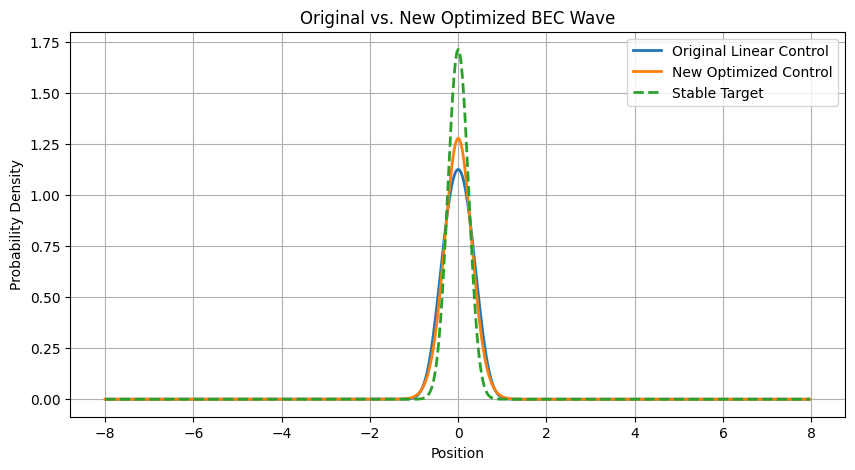

In [39]:
# @title
# Evaluate our new smooth-control optimization

# Simulate the wave using optimized coefficients
new_optimized_wave = simulate_smooth(stable_result.x)

# Calculate its probability density
new_optimized_density = np.abs(new_optimized_wave)**2

# Measure the density error
new_density_error = np.sqrt(
    np.sum(
        (new_optimized_density - stable_target_density)**2
    ) * dx
)

# Calculate the full wave-function infidelity
new_overlap = np.sum(
    np.conj(target_wave) * new_optimized_wave
) * dx

new_infidelity = 1 - np.abs(new_overlap)**2

# Print our results
print("Original density error:", round(density_error, 6))
print("New optimized density error:", round(new_density_error, 6))
print("New infidelity:", round(float(np.real(new_infidelity)), 6))

# Plot the comparison
plt.figure(figsize=(10, 5))

plt.plot(
    x, final_density,
    label="Original Linear Control",
    linewidth=2
)

plt.plot(
    x, new_optimized_density,
    label="New Optimized Control",
    linewidth=2
)

plt.plot(
    x, stable_target_density,
    label="Stable Target",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("Original vs. New Optimized BEC Wave")
plt.legend()
plt.grid(True)
plt.show()

----------------------------------------------------------------------------
This code plots the original linear control and the newly optimized control over time. It also prints the starting, ending, minimum, and maximum control strengths.

Why we're using it: We want to verify that the optimized control starts at 1, ends at 100, and behaves reasonably throughout the simulation. If it goes outside the allowed range, we'll need to add constraints. How to explain it in your presentation After optimizing the BEC wave, we examined the control function to understand how the algorithm achieved its improved result. We compared the original linear control against the optimized control and checked its minimum and maximum values. This helped us determine whether the optimized solution respected our control requirements.

Starting control: 1.0
Ending control: 100.0
Minimum control: 1.0
Maximum control: 101.3558


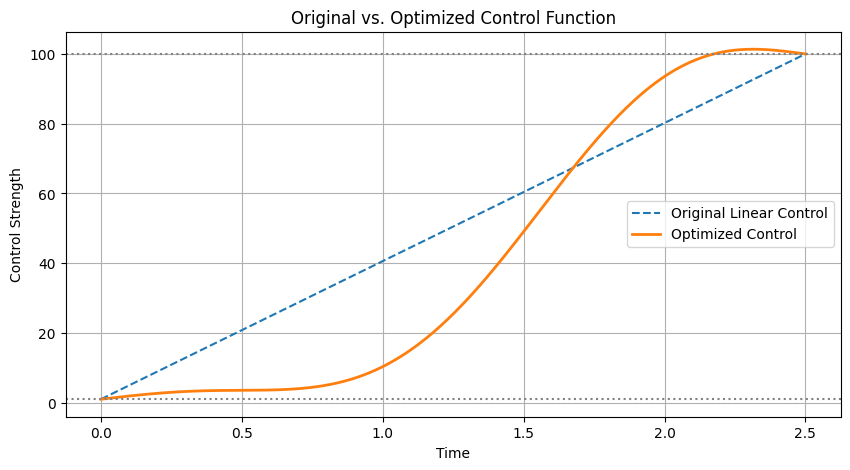

In [18]:
# @title
# Check our optimized control function

control_times = np.linspace(0, T, 500)

optimized_controls = np.array([
    smooth_control(t, stable_result.x)
    for t in control_times
])

linear_controls = u0 + (uT - u0) * control_times / T

print("Starting control:", round(optimized_controls[0], 4))
print("Ending control:", round(optimized_controls[-1], 4))
print("Minimum control:", round(optimized_controls.min(), 4))
print("Maximum control:", round(optimized_controls.max(), 4))

plt.figure(figsize=(10, 5))

plt.plot(
    control_times,
    linear_controls,
    label="Original Linear Control",
    linestyle="--"
)

plt.plot(
    control_times,
    optimized_controls,
    label="Optimized Control",
    linewidth=2
)

plt.axhline(1, color="gray", linestyle=":")
plt.axhline(100, color="gray", linestyle=":")

plt.xlabel("Time")
plt.ylabel("Control Strength")
plt.title("Original vs. Optimized Control Function")
plt.legend()
plt.grid(True)
plt.show()


-------------------------------------------------------------------------------
This code continues simulating the optimized BEC wave after the control reaches its final value of 100. It measures the wave's width over time and creates a graph showing whether that width stays constant or oscillates.

Our researcher wants the wave to reach a stable final state without unwanted oscillations.
A small width variation would support the idea that our optimized wave is relatively stable.
A large variation would indicate that the wave is still oscillating and that the control needs improvement.

Width is only one stability measurement, so we'll eventually check the full probability density as well.

After optimizing the BEC wave, we tested whether it remained stable when the control was held constant. We continued the simulation for an additional time period and measured the wave's width at each step. This allowed us to identify whether the optimized wave continued oscillating or maintained a consistent shape.
Stability is important because our goal is not only to squeeze the wave but also to reach a desired final state without unwanted movement.

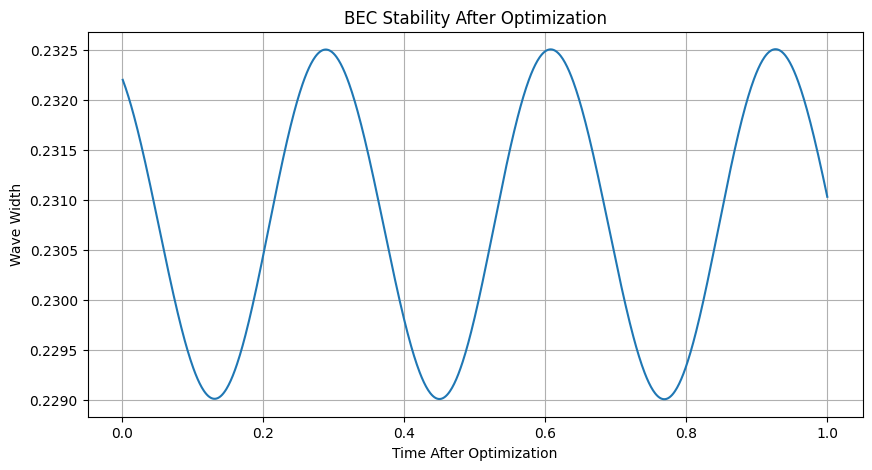

Minimum width: 0.229008
Maximum width: 0.232504
Width variation: 0.003496


In [19]:
# @title
# Test stability after optimization

# Start with our optimized final wave
wave = new_optimized_wave.copy()

# Keep the final control fixed at 100
V_hold = 0.5 * 100.0 * x**2

# Continue simulation for 1 additional time unit
hold_steps = 1000

width_history = []
hold_times = []

for step in range(hold_steps):

    # First half-step
    wave *= np.exp(
        -0.5j * dt * (V_hold + np.abs(wave)**2)
    )

    # Kinetic step
    wave_k = np.fft.fft(wave)
    wave_k *= np.exp(-0.5j * k**2 * dt)
    wave = np.fft.ifft(wave_k)

    # Second half-step
    wave *= np.exp(
        -0.5j * dt * (V_hold + np.abs(wave)**2)
    )

    # Measure wave width
    density = np.abs(wave)**2

    width = np.sqrt(
        np.sum(x**2 * density) * dx
    )

    width_history.append(width)
    hold_times.append((step + 1) * dt)

# Plot width over time
plt.figure(figsize=(10, 5))
plt.plot(hold_times, width_history)

plt.xlabel("Time After Optimization")
plt.ylabel("Wave Width")
plt.title("BEC Stability After Optimization")
plt.grid(True)
plt.show()

print("Minimum width:", round(min(width_history), 6))
print("Maximum width:", round(max(width_history), 6))
print(
    "Width variation:",
    round(max(width_history) - min(width_history), 6)
)


-------------------------------------------------------------------------------
This code checks how sensitive the BEC simulation is to the time step by running it with the same optimized controls using steps of 0.001 and 0.0005. It calculates the difference between the final probability densities and plots them for comparison. If the difference is small and the curves overlap, that suggests the density result is consistent under time-step refinement, helping validate the traditional solver before using it to train the AI neural operator.

Time-step difference: 2.5976259204165597e-06


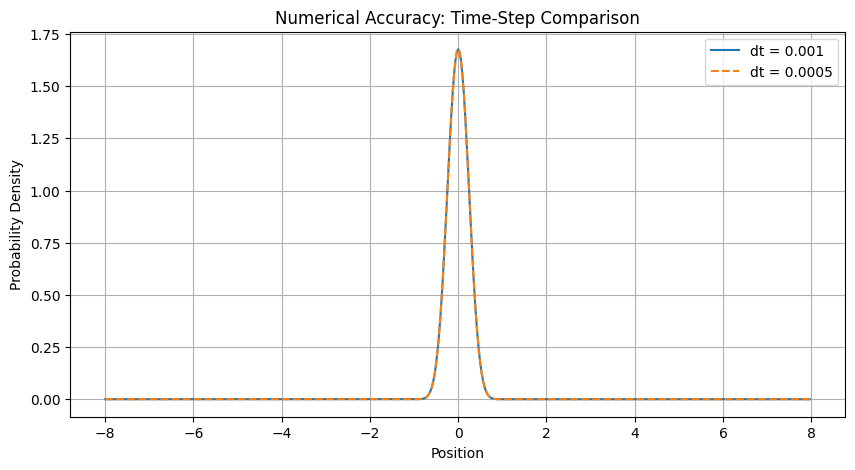

 The numerical accuracy test looks very good! The two lines overlap almost perfectly, 
 which means our simulation produces nearly identical results when we use a smaller time step. 
 this is a very small difference. It suggests that our numerical results are consistent when we reduce the time step. Your graph confirms this visually: the blue and orange lines are almost indistinguishable. 
 Why this matters: Before training our AI neural operator, we need confidence that the traditional solver is producing reliable results. 
 
 Otherwise, the AI could learn from inaccurate simulation data. We still need to test spatial resolution and full wave-function accuracy, but this is a useful first validation.


In [20]:
# @title
# Test numerical accuracy using a smaller time step

def simulate_with_dt(coefficients, test_dt):
    wave = psi_start.copy()
    test_steps = int(round(T / test_dt))
    actual_dt = T / test_steps

    for step in range(test_steps):
        t_mid = (step + 0.5) * actual_dt
        u = smooth_control(t_mid, coefficients)

        V = 0.5 * u * x**2

        wave *= np.exp(
            -0.5j * actual_dt * (V + np.abs(wave)**2)
        )

        wave_k = np.fft.fft(wave)
        wave_k *= np.exp(
            -0.5j * k**2 * actual_dt
        )
        wave = np.fft.ifft(wave_k)

        wave *= np.exp(
            -0.5j * actual_dt * (V + np.abs(wave)**2)
        )

    return wave

# Compare our original time step with a smaller one
wave_dt1 = simulate_with_dt(stable_result.x, 0.001)
wave_dt2 = simulate_with_dt(stable_result.x, 0.0005)

# Compare probability densities
density_dt1 = np.abs(wave_dt1)**2
density_dt2 = np.abs(wave_dt2)**2

time_step_error = np.sqrt(
    np.sum((density_dt1 - density_dt2)**2) * dx
)

print("Time-step difference:", time_step_error)

plt.figure(figsize=(10, 5))
plt.plot(x, density_dt1, label="dt = 0.001")
plt.plot(x, density_dt2, "--", label="dt = 0.0005")

plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("Numerical Accuracy: Time-Step Comparison")
plt.legend()
plt.grid(True)
plt.show()


print(" The numerical accuracy test looks very good! The two lines overlap almost perfectly, \n which means our simulation produces nearly identical results when we use a smaller time step. \n this is a very small difference. It suggests that our numerical results are consistent when we reduce the time step. Your graph confirms this visually: the blue and orange lines are almost indistinguishable. \n Why this matters: Before training our AI neural operator, we need confidence that the traditional solver is producing reliable results. \n \n Otherwise, the AI could learn from inaccurate simulation data. We still need to test spatial resolution and full wave-function accuracy, but this is a useful first validation.")


-------------------------------------------------------------------------------
This code creates a dataset for training your AI model.
It randomly selects 30 sets of three control coefficients, each between −20 and 20, and runs your traditional BEC solver for each set.
It saves the coefficients as inputs and the resulting wave’s real and imaginary components as outputs.
It also measures how long data generation takes and saves everything in bec_training_data.npz.
The fixed random seed makes the coefficient choices reproducible.

**It generates training examples; it does not train the AI yet.**

In [21]:
# @title
print("Before training an AI model, we need examples it can learn from. \nOur traditional solver will generate these examples by running simulations with different control functions. \nEach example will contain a set of control coefficients and the resulting wave function.\n\n")
# Generate training data for our neural operator

import numpy as np
import time

np.random.seed(42)

# Number of simulations to generate
num_samples = 30

# Store controls and resulting waves
control_data = []
wave_data = []

start_time = time.perf_counter()

for i in range(num_samples):

    # Generate random control adjustments
    coefficients = np.random.uniform(
        -20, 20, size=3
    )

    # Run our traditional GPE solver
    wave = simulate_smooth(coefficients)

    # Save the control coefficients
    control_data.append(coefficients)

    # Save real and imaginary wave components
    wave_data.append(
        np.stack([wave.real, wave.imag], axis=-1)
    )

control_data = np.array(control_data)
wave_data = np.array(wave_data)

generation_time = time.perf_counter() - start_time

print("Training data generated!")
print("Control data shape:", control_data.shape)
print("Wave data shape:", wave_data.shape)
print("Generation time:", round(generation_time, 2), "seconds")

# Save the dataset
np.savez(
    "bec_training_data.npz",
    controls=control_data,
    waves=wave_data
)

print("Dataset saved as bec_training_data.npz")


Before training an AI model, we need examples it can learn from. 
Our traditional solver will generate these examples by running simulations with different control functions. 
Each example will contain a set of control coefficients and the resulting wave function.


Training data generated!
Control data shape: (30, 3)
Wave data shape: (30, 512, 2)
Generation time: 12.51 seconds
Dataset saved as bec_training_data.npz


-----------------------------------------------------------------------------
This is the next step after generating your dataset. It loads the 30 saved simulations, shuffles them reproducibly while keeping each control set paired with its wave, and divides them into:
- 20 training examples: Used to teach the model.
- 5 validation examples: Used to guide model choices during development.
- 5 testing examples: Kept aside to evaluate the finished model on unseen examples.
It then converts the data into PyTorch tensors, the format your AI training code needs. The inputs are the three control coefficients; the outputs are the corresponding wave’s real and imaginary components.
This prepares the data—it still doesn’t train the model.

In [22]:
# @title
print ("Before building our neural operator, we need to separate the data so we can measure whether the AI can predict waves it hasn't seen before. \nWe'll use 20 simulations for training, 5 for validation, and 5 for testing.\n\n")

# Split our BEC dataset into training, validation, and testing

import numpy as np
import torch

# Load the saved dataset
data = np.load("bec_training_data.npz")

controls = data["controls"]
waves = data["waves"]

# Shuffle the examples reproducibly
rng = np.random.default_rng(42)
indices = rng.permutation(len(controls))

controls = controls[indices]
waves = waves[indices]

# Divide the dataset
train_controls = controls[:20]
val_controls = controls[20:25]
test_controls = controls[25:30]

train_waves = waves[:20]
val_waves = waves[20:25]
test_waves = waves[25:30]

# Convert arrays into PyTorch tensors
train_x = torch.tensor(train_controls, dtype=torch.float32)
val_x = torch.tensor(val_controls, dtype=torch.float32)
test_x = torch.tensor(test_controls, dtype=torch.float32)

train_y = torch.tensor(train_waves, dtype=torch.float32)
val_y = torch.tensor(val_waves, dtype=torch.float32)
test_y = torch.tensor(test_waves, dtype=torch.float32)

print("Training examples:", len(train_x))
print("Validation examples:", len(val_x))
print("Testing examples:", len(test_x))

print("Input shape:", train_x.shape)
print("Output shape:", train_y.shape)


Before building our neural operator, we need to separate the data so we can measure whether the AI can predict waves it hasn't seen before. 
We'll use 20 simulations for training, 5 for validation, and 5 for testing.


Training examples: 20
Validation examples: 5
Testing examples: 5
Input shape: torch.Size([20, 3])
Output shape: torch.Size([20, 512, 2])


In [48]:
# @title Expand Training Data: 20 to 100 Examples

import numpy as np
import torch
import time

# Preserve the original training set.
# This also prevents duplicate additions if this cell is rerun.
if "original_train_x" not in globals():
    original_train_x = train_x.clone()
    original_train_y = train_y.clone()

# Separate random seed for the additional examples
extra_rng = np.random.default_rng(2026)
extra_controls = extra_rng.uniform(-20, 20, size=(80, 3))

extra_waves = []
start = time.perf_counter()

for i, coefficients in enumerate(extra_controls):
    wave = simulate_smooth(coefficients)

    extra_waves.append(
        np.stack([wave.real, wave.imag], axis=-1)
    )

    if (i + 1) % 20 == 0:
        print(f"Generated {i + 1}/80 additional examples")

extra_generation_time = time.perf_counter() - start

extra_x = torch.tensor(extra_controls, dtype=torch.float32)
extra_y = torch.tensor(np.array(extra_waves), dtype=torch.float32)

train_x = torch.cat([original_train_x, extra_x], dim=0)
train_y = torch.cat([original_train_y, extra_y], dim=0)

# Save the expanded dataset with separate splits
np.savez(
    "bec_expanded_data.npz",
    train_controls=train_x.numpy(),
    train_waves=train_y.numpy(),
    val_controls=val_x.numpy(),
    val_waves=val_y.numpy(),
    exploratory_test_controls=test_x.numpy(),
    exploratory_test_waves=test_y.numpy()
)

print("\nTraining examples:", len(train_x))
print("Validation examples:", len(val_x))
print("Additional generation time:",
      round(extra_generation_time, 2), "seconds")
print("Saved: bec_expanded_data.npz")
print("The previously inspected test cases are exploratory.")

Generated 20/80 additional examples
Generated 40/80 additional examples
Generated 60/80 additional examples
Generated 80/80 additional examples

Training examples: 100
Validation examples: 5
Additional generation time: 31.81 seconds
Saved: bec_expanded_data.npz
The previously inspected test cases are exploratory.


Result explination:

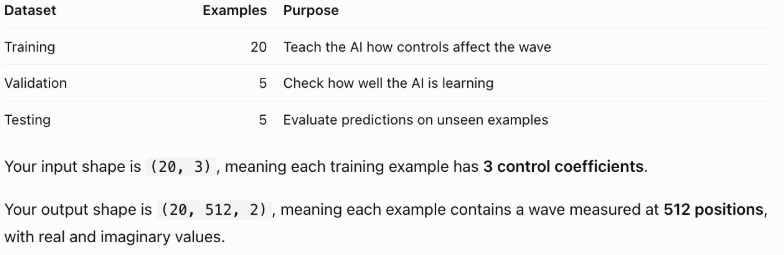

------------------------------------------------------------------------------
This code builds the AI model that will learn to predict the final BEC wave from three control coefficients. It combines those coefficients with 512 spatial positions, then passes them through two layers that learn broad patterns using Fourier frequencies and local features using convolution layers. At each position, it outputs two numbers: the predicted real and imaginary parts of the wave function. Finally, it creates the model and prints its number of trainable parameters. It does not train the model yet.


- This is an FNO-style model. It becomes physics-informed only if you add physics constraints during training.


In [65]:
# @title
print("A Fourier Neural Operator is a type of AI model that learns relationships between functions.\n In our project, we want it to learn how different control functions affect the final BEC wave.\nWe're going to build a small FNO-style model using PyTorch. For now, we're only creating the model, not training it yet.\n")
# Build a small Fourier Neural Operator

import torch
import torch.nn as nn

# Fourier layer: learns patterns in frequency space
class SpectralConv1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.modes = modes

        self.weights = nn.Parameter(
            0.02 * torch.randn(
                width, width, modes, dtype=torch.cfloat
            )
        )

    def forward(self, x):
        batch, width, n = x.shape

        # Convert spatial data into Fourier frequencies
        x_ft = torch.fft.rfft(x, dim=-1)

        # Learn from selected Fourier modes
        out_ft = torch.zeros(
            batch, width, n // 2 + 1,
            dtype=torch.cfloat,
            device=x.device
        )

        modes = min(self.modes, x_ft.shape[-1])

        out_ft[:, :, :modes] = torch.einsum(
            "bim,iom->bom",
            x_ft[:, :, :modes],
            self.weights[:, :, :modes]
        )

        # Convert back into spatial representation
        return torch.fft.irfft(out_ft, n=n, dim=-1)


# Neural operator model
class BECNeuralOperator(nn.Module):
    def __init__(self, width=32, modes=16):
        super().__init__()

        self.input_layer = nn.Linear(4, width)

        self.spectral1 = SpectralConv1d(width, modes)
        self.spectral2 = SpectralConv1d(width, modes)

        self.local1 = nn.Conv1d(width, width, 1)
        self.local2 = nn.Conv1d(width, width, 1)

        self.output_layer = nn.Linear(width, 2)

    def forward(self, controls):
        batch = controls.shape[0]

        # Create position coordinates
        positions = (
    -8.0
    + torch.arange(
        512,
        device=controls.device,
        dtype=controls.dtype
    ) * (16.0 / 512)
).reshape(1, 512, 1)

        positions = positions.repeat(batch, 1, 1)

        # Repeat controls across spatial positions
        expanded_controls = controls.unsqueeze(1).repeat(
            1, 512, 1
        )

        # Combine control inputs with position
        x = torch.cat(
            [expanded_controls, positions], dim=-1
        )

        x = self.input_layer(x)
        x = x.permute(0, 2, 1)

        # Fourier layers
        x = torch.relu(
            self.spectral1(x) + self.local1(x)
        )

        x = torch.relu(
            self.spectral2(x) + self.local2(x)
        )

        x = x.permute(0, 2, 1)

        # Predict real and imaginary wave components
        return self.output_layer(x)


# Create the model
model = BECNeuralOperator()

print("Neural operator created successfully!")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()))

A Fourier Neural Operator is a type of AI model that learns relationships between functions.
 In our project, we want it to learn how different control functions affect the final BEC wave.
We're going to build a small FNO-style model using PyTorch. For now, we're only creating the model, not training it yet.

Neural operator created successfully!
Trainable parameters: 35106


**NOW To train the data to predict how the BEC wave responds to different controls**

This code trains our AI model using the BEC simulations we generated earlier. The model predicts the final wave from the control settings, compares its prediction with the traditional solver’s result, and adjusts itself to reduce mistakes. It repeats this process 150 times. We also check its predictions on separate validation examples to see whether it can handle examples it did not train on. Finally, the code reports the training time and plots the training and validation errors to show its progress.

Our traditional numerical solver calculates how a BEC wave evolves by solving the Gross–Pitaevskii equation. We want to determine whether an AI neural operator can learn that relationship and predict the final wave without repeatedly performing the full numerical simulation.

The training and validation losses help us measure whether the AI is learning. However, we still need to evaluate its predictions on the five test examples before deciding how accurate it is. How to explain it in your presentation We trained our Fourier Neural Operator using simulation data generated by our traditional GPE solver. The model learned to connect different control settings with their resulting BEC wave functions. We trained the model for 150 epochs and measured both training and validation errors to track its performance. Our goal was to determine whether the neural operator could accurately approximate the traditional solver while potentially reducing computation time.


Training with 20 examples...
Epoch 50: train MSE=0.005683, validation MSE=0.018627
Epoch 100: train MSE=0.002651, validation MSE=0.018797
Epoch 150: train MSE=0.001614, validation MSE=0.018626
Validation wave error: 74.41%
Training time: 5.63 seconds

Training with 100 examples...
Epoch 50: train MSE=0.009031, validation MSE=0.013217
Epoch 100: train MSE=0.005942, validation MSE=0.011172
Epoch 150: train MSE=0.004625, validation MSE=0.010653
Validation wave error: 55.16%
Training time: 22.91 seconds


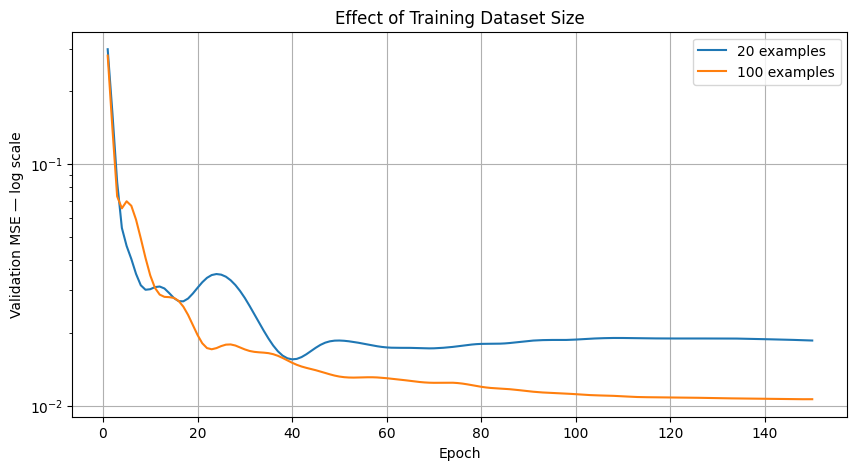


FINAL VALIDATION COMPARISON
20 examples: MSE=0.018626, relative wave error=74.41%
100 examples: MSE=0.010653, relative wave error=55.16%


In [49]:
# @title Controlled Experiment: 20 vs 100 Training Examples

import copy
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

# Identical initial weights for both experiments
torch.manual_seed(42)
initial_model = BECNeuralOperator()
initial_weights = copy.deepcopy(initial_model.state_dict())

epochs = 150
experiment_results = {}

for label, inputs, targets in [
    ("20 examples", original_train_x, original_train_y),
    ("100 examples", train_x, train_y)
]:
    print(f"\nTraining with {label}...")

    # Start each experiment from the same weights
    candidate = BECNeuralOperator()
    candidate.load_state_dict(initial_weights)

    optimizer = torch.optim.Adam(
        candidate.parameters(), lr=0.001
    )

    train_history = []
    val_history = []

    start = time.perf_counter()

    for epoch in range(epochs):
        candidate.train()
        optimizer.zero_grad()

        prediction = candidate(inputs)
        loss = torch.mean((prediction - targets)**2)

        loss.backward()
        optimizer.step()

        train_history.append(loss.item())

        candidate.eval()
        with torch.no_grad():
            val_prediction = candidate(val_x)
            val_loss = torch.mean(
                (val_prediction - val_y)**2
            ).item()

        val_history.append(val_loss)

        if (epoch + 1) % 50 == 0:
            print(
                f"Epoch {epoch + 1}: "
                f"train MSE={loss.item():.6f}, "
                f"validation MSE={val_loss:.6f}"
            )

    elapsed = time.perf_counter() - start

    with torch.no_grad():
        difference = (
            candidate(val_x) - val_y
        ).reshape(len(val_y), -1)

        reference = val_y.reshape(len(val_y), -1)

        relative_error = (
            torch.linalg.vector_norm(difference, dim=1)
            / torch.linalg.vector_norm(reference, dim=1)
        ).mean().item()

    experiment_results[label] = {
        "training_losses": train_history,
        "validation_losses": val_history,
        "training_time": elapsed,
        "validation_relative_error": relative_error
    }

    print(f"Validation wave error: {100 * relative_error:.2f}%")
    print(f"Training time: {elapsed:.2f} seconds")

    # Keep the trained 100-example model for subsequent work
    if label == "100 examples":
        model = candidate
        training_losses = train_history
        validation_losses = val_history
        training_time = elapsed

# Compare validation performance over training
plt.figure(figsize=(10, 5))

for label, result in experiment_results.items():
    plt.semilogy(
        range(1, epochs + 1),
        result["validation_losses"],
        label=label
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MSE — log scale")
plt.title("Effect of Training Dataset Size")
plt.legend()
plt.grid(True)
plt.show()

print("\nFINAL VALIDATION COMPARISON")
for label, result in experiment_results.items():
    print(
        f"{label}: "
        f"MSE={result['validation_losses'][-1]:.6f}, "
        f"relative wave error="
        f"{100 * result['validation_relative_error']:.2f}%"
    )

Effect of training dataset size
We compared 20 and 100 training examples using identical initial model weights, the same validation cases, and 150 training epochs. Increasing the training set reduced validation MSE from 0.018626 to 0.010653 and mean relative wave-function error from 74.41% to 55.16%.

This provides evidence that limited training data contributes to prediction error. However, substantial error remains. The conclusion is preliminary because the experiment uses five validation cases and one model initialization. Generating the additional 80 examples took 31.81 seconds, which must be included in the surrogate’s computational cost.

**Now we need to measure how accurately the neural operator predicts those wave functions.**

What this code does:

It gives the trained AI five control settings it did not see during training. It compares the predicted wave functions with the results from our traditional GPE solver and calculates the relative L2 error. It also plots the predicted and actual probability densities for one test example.

This is how we determine whether the neural operator can predict new BEC wave functions accurately, rather than simply memorizing training examples.

Relative L2 errors for each test example:
Test 1: 0.7578 (75.78%)
Test 2: 0.7799 (77.99%)
Test 3: 0.7838 (78.38%)
Test 4: 0.5620 (56.20%)
Test 5: 0.4041 (40.41%)

Average test error: 65.75%


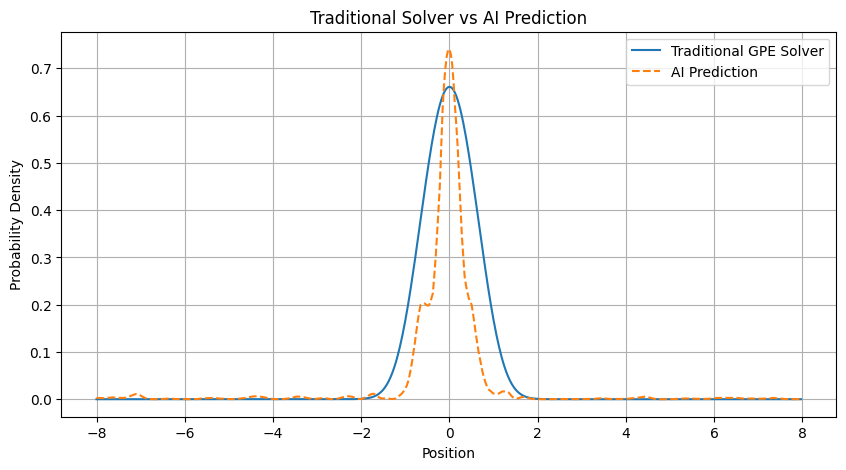

In [50]:
# @title
# Test AI predictions against the traditional GPE solver

import numpy as np
import matplotlib.pyplot as plt
import torch

model.eval()

with torch.no_grad():
    test_predictions = model(test_x).numpy()

actual_waves = test_y.numpy()

# Calculate relative L2 errors for all five test examples
relative_errors = []

for i in range(len(test_predictions)):
    predicted = test_predictions[i]
    actual = actual_waves[i]

    error = np.linalg.norm(predicted - actual)
    reference = np.linalg.norm(actual)

    relative_errors.append(error / reference)

relative_errors = np.array(relative_errors)

print("Relative L2 errors for each test example:")

for i, error in enumerate(relative_errors):
    print(f"Test {i+1}: {error:.4f} ({error*100:.2f}%)")

print()
print(f"Average test error: {relative_errors.mean()*100:.2f}%")

# Compare predicted and actual probability densities
x_plot = np.linspace(-8, 8, 512, endpoint=False)

actual_density = np.sum(actual_waves[0]**2, axis=-1)
predicted_density = np.sum(test_predictions[0]**2, axis=-1)

plt.figure(figsize=(10, 5))

plt.plot(x_plot, actual_density,
         label="Traditional GPE Solver")

plt.plot(x_plot, predicted_density,
         "--", label="AI Prediction")

plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("Traditional Solver vs AI Prediction")
plt.legend()
plt.grid(True)
plt.show()


After training our neural operator, we tested it using five previously unseen examples. We compared the AI-generated wave functions against our traditional GPE simulation using relative L2 error. This allowed us to evaluate how accurately the AI generalized to new control settings. We also compared probability density plots to visually identify differences between the two methods.

-------------------------------------------------------------------------------
This code compares how long the traditional BEC solver and the trained AI model take to produce a result for the same test control settings. It runs each method several times and averages the times, then calculates how much faster the AI prediction is. It also includes the time spent generating training data and training the model to estimate the break-even point—how many predictions are needed before the AI saves time overall.

In [61]:
# @title
print("Next step — Compare computation times\n\n")

# Compare traditional solver and AI prediction times

import time
import numpy as np
import torch

# Use a control setting from our test dataset
sample_controls = test_controls[0]

# Time the traditional GPE solver
traditional_times = []

for i in range(5):
    start = time.perf_counter()
    traditional_wave = simulate_smooth(sample_controls)
    traditional_times.append(time.perf_counter() - start)

# Time the neural operator
model.eval()
sample_tensor = test_x[0:1]

ai_times = []

with torch.no_grad():
    # Warm-up prediction
    model(sample_tensor)

    for i in range(20):
        start = time.perf_counter()
        ai_wave = model(sample_tensor)
        ai_times.append(time.perf_counter() - start)

traditional_average = np.mean(traditional_times)
ai_average = np.mean(ai_times)

speedup = traditional_average / ai_average

print(f"Traditional solver: {traditional_average:.6f} seconds")
print(f"AI prediction: {ai_average:.6f} seconds")
print(f"Prediction speedup: {speedup:.2f}x")

# Include the cost of generating training data
data_generation_time = generation_time + extra_generation_time
total_ai_setup_time = data_generation_time + training_time

time_saved_per_prediction = traditional_average - ai_average

if time_saved_per_prediction > 0:
    break_even = np.ceil(
        total_ai_setup_time / time_saved_per_prediction
    )
    print(f"Estimated break-even queries: {int(break_even)}")
else:
    print("No break-even point: AI prediction is slower.")


Next step — Compare computation times


Traditional solver: 1.185887 seconds
AI prediction: 0.001119 seconds
Prediction speedup: 1060.04x
Estimated break-even queries: 57


In [51]:
# @title Diagnose Neural Prediction Errors

predicted_complex = (
    test_predictions[..., 0] + 1j * test_predictions[..., 1]
)
actual_complex = (
    actual_waves[..., 0] + 1j * actual_waves[..., 1]
)

for i, (predicted, actual) in enumerate(
    zip(predicted_complex, actual_complex), start=1
):
    predicted_mass = np.sum(np.abs(predicted)**2) * dx
    actual_mass = np.sum(np.abs(actual)**2) * dx

    # Remove only a physically irrelevant global phase
    overlap = np.vdot(actual, predicted)
    aligned = predicted * np.exp(-1j * np.angle(overlap))

    aligned_error = (
        np.linalg.norm(aligned - actual)
        / np.linalg.norm(actual)
    )

    predicted_density = np.abs(predicted)**2
    actual_density = np.abs(actual)**2

    density_error = (
        np.linalg.norm(predicted_density - actual_density)
        / np.linalg.norm(actual_density)
    )

    print(f"\nTest {i}")
    print(f"Actual probability:          {actual_mass:.4f}")
    print(f"Predicted probability:       {predicted_mass:.4f}")
    print(f"Phase-aligned wave error:    {100 * aligned_error:.2f}%")
    print(f"Relative density error:      {100 * density_error:.2f}%")


Test 1
Actual probability:          1.0000
Predicted probability:       0.5757
Phase-aligned wave error:    72.08%
Relative density error:      46.36%

Test 2
Actual probability:          1.0000
Predicted probability:       0.5176
Phase-aligned wave error:    77.26%
Relative density error:      57.21%

Test 3
Actual probability:          1.0000
Predicted probability:       0.2652
Phase-aligned wave error:    76.28%
Relative density error:      71.83%

Test 4
Actual probability:          1.0000
Predicted probability:       0.8267
Phase-aligned wave error:    55.62%
Relative density error:      49.83%

Test 5
Actual probability:          1.0000
Predicted probability:       0.8376
Phase-aligned wave error:    40.28%
Relative density error:      26.16%


In [52]:
# @title Diagnostic: Does Normalization Improve Density Accuracy?

raw_errors = []
normalized_errors = []

for i, (predicted, actual) in enumerate(
    zip(predicted_complex, actual_complex), start=1
):
    predicted_mass = np.sum(np.abs(predicted)**2) * dx

    if predicted_mass < 1e-12:
        print(f"Test {i}: prediction has near-zero probability.")
        continue

    normalized_prediction = predicted / np.sqrt(predicted_mass)

    actual_density = np.abs(actual)**2
    raw_density = np.abs(predicted)**2
    normalized_density = np.abs(normalized_prediction)**2

    reference_norm = np.linalg.norm(actual_density)

    raw_error = (
        np.linalg.norm(raw_density - actual_density)
        / reference_norm
    )

    normalized_error = (
        np.linalg.norm(normalized_density - actual_density)
        / reference_norm
    )

    raw_errors.append(raw_error)
    normalized_errors.append(normalized_error)

    print(
        f"Test {i}: density error "
        f"{100 * raw_error:.2f}% before normalization, "
        f"{100 * normalized_error:.2f}% after"
    )

if raw_errors:
    print(
        "\nMean density error before:",
        f"{100 * np.mean(raw_errors):.2f}%"
    )
    print(
        "Mean density error after:",
        f"{100 * np.mean(normalized_errors):.2f}%"
    )

Test 1: density error 46.36% before normalization, 54.49% after
Test 2: density error 57.21% before normalization, 87.55% after
Test 3: density error 71.83% before normalization, 57.61% after
Test 4: density error 49.83% before normalization, 42.17% after
Test 5: density error 26.16% before normalization, 33.88% after

Mean density error before: 50.28%
Mean density error after: 55.14%


In [54]:
# @title Prepare Space-Time Data for Physics-Informed Training

import numpy as np
import time

def simulate_trajectory(coefficients, save_every=25):
    # Same initial state and equation as our existing solver
    wave = psi_start.copy()

    saved_waves = [wave.copy()]
    saved_times = [0.0]

    for step in range(steps):
        t_mid = (step + 0.5) * dt
        control = smooth_control(t_mid, coefficients)
        potential = 0.5 * control * x**2

        wave *= np.exp(
            -0.5j * dt * (potential + np.abs(wave)**2)
        )

        wave_k = np.fft.fft(wave)
        wave_k *= np.exp(-0.5j * k**2 * dt)
        wave = np.fft.ifft(wave_k)

        wave *= np.exp(
            -0.5j * dt * (potential + np.abs(wave)**2)
        )

        if (step + 1) % save_every == 0 or step + 1 == steps:
            saved_waves.append(wave.copy())
            saved_times.append((step + 1) * dt)

    return np.array(saved_times), np.array(saved_waves)


# Reuse the original training and validation controls.
# Validation controls remain separate from training controls.
trajectory_train_controls = original_train_x.detach().cpu().numpy()
trajectory_val_controls = val_x.detach().cpu().numpy()

start = time.perf_counter()

trajectory_train_waves = []
trajectory_val_waves = []

for coefficients in trajectory_train_controls:
    trajectory_times, waves = simulate_trajectory(coefficients)
    trajectory_train_waves.append(waves)

for coefficients in trajectory_val_controls:
    trajectory_times, waves = simulate_trajectory(coefficients)
    trajectory_val_waves.append(waves)

trajectory_train_waves = np.array(trajectory_train_waves)
trajectory_val_waves = np.array(trajectory_val_waves)

trajectory_generation_time = time.perf_counter() - start

np.savez(
    "bec_spacetime_data.npz",
    x=x.copy(),
    times=trajectory_times,
    train_controls=trajectory_train_controls,
    train_waves=trajectory_train_waves,
    val_controls=trajectory_val_controls,
    val_waves=trajectory_val_waves
)

print("Space-time data saved.")
print("Training wave shape:", trajectory_train_waves.shape)
print("Validation wave shape:", trajectory_val_waves.shape)
print("Dimensions: control examples, saved times, spatial positions")
print(
    "Generation time:",
    round(trajectory_generation_time, 2),
    "seconds"
)
print("These arrays contain complex waves, not densities.")
print("Your existing trained model has not been changed.")

Space-time data saved.
Training wave shape: (20, 101, 512)
Validation wave shape: (5, 101, 512)
Dimensions: control examples, saved times, spatial positions
Generation time: 10.79 seconds
These arrays contain complex waves, not densities.
Your existing trained model has not been changed.


In [62]:
# @title P1: Verify Solver Resolution and Runtime

import numpy as np
import pandas as pd
import time

# Local solver: does not change the notebook's existing grid or settings
def verification_solve(coefficients, grid_size, time_step):
    domain_length = 16.0
    spacing = domain_length / grid_size

    positions = np.linspace(
        -8.0, 8.0, grid_size, endpoint=False
    )

    frequencies = 2 * np.pi * np.fft.fftfreq(
        grid_size, d=spacing
    )

    wave = np.exp(-positions**2 / 2).astype(complex)
    wave /= np.sqrt(np.sum(np.abs(wave)**2) * spacing)

    number_of_steps = int(round(T / time_step))
    actual_dt = T / number_of_steps

    kinetic_factor = np.exp(
        -0.5j * frequencies**2 * actual_dt
    )

    start = time.perf_counter()

    for step in range(number_of_steps):
        midpoint = (step + 0.5) * actual_dt
        control = smooth_control(midpoint, coefficients)
        potential = 0.5 * control * positions**2

        wave *= np.exp(
            -0.5j * actual_dt
            * (potential + np.abs(wave)**2)
        )

        wave = np.fft.ifft(
            np.fft.fft(wave) * kinetic_factor
        )

        wave *= np.exp(
            -0.5j * actual_dt
            * (potential + np.abs(wave)**2)
        )

    runtime = time.perf_counter() - start

    return wave, runtime


def relative_wave_difference(first, reference):
    return (
        np.linalg.norm(first - reference)
        / np.linalg.norm(reference)
    )


# Check the linear baseline and the same five validation controls.
# These are numerical-verification cases, not new training examples.
verification_controls = np.vstack([
    np.zeros((1, 3)),
    trajectory_val_controls
])

verification_rows = []

for case, coefficients in enumerate(verification_controls):
    name = "Linear baseline" if case == 0 else f"Validation {case}"

    # Time refinement at fixed spatial resolution
    coarse, runtime = verification_solve(
        coefficients, 512, 0.001
    )
    fine_time, _ = verification_solve(
        coefficients, 512, 0.0005
    )

    # Spatial refinement at fixed time step
    fine_space, _ = verification_solve(
        coefficients, 1024, 0.0005
    )
    finest_space, _ = verification_solve(
        coefficients, 2048, 0.0005
    )

    # Nested grids share these spatial positions
    time_difference = relative_wave_difference(
        coarse, fine_time
    )

    spatial_difference_512 = relative_wave_difference(
        fine_time, fine_space[::2]
    )

    spatial_difference_1024 = relative_wave_difference(
        fine_space, finest_space[::2]
    )

    density_difference = (
        np.linalg.norm(
            np.abs(coarse)**2 - np.abs(finest_space[::4])**2
        )
        / np.linalg.norm(np.abs(finest_space[::4])**2)
    )

    verification_rows.append({
        "Case": name,
        "Time refinement wave difference (%)":
            100 * time_difference,
        "512 to 1024 wave difference (%)":
            100 * spatial_difference_512,
        "1024 to 2048 wave difference (%)":
            100 * spatial_difference_1024,
        "Density difference vs refined solve (%)":
            100 * density_difference,
        "512-grid evolution time (s)": runtime
    })

    print(f"Finished: {name}")

baseline_verification = pd.DataFrame(verification_rows)

print("\nP1: NUMERICAL VERIFICATION")
print(baseline_verification.round(6).to_string(index=False))

baseline_verification.to_csv(
    "P1_baseline_verification.csv", index=False
)

print("\nDifferences measure sensitivity to numerical refinement.")
print("The refined solution is not an exact analytical solution.")
print("Runtime measures the evolution loop, excluding setup.")
print("Existing models and simulation settings are unchanged.")

Finished: Linear baseline
Finished: Validation 1
Finished: Validation 2
Finished: Validation 3
Finished: Validation 4
Finished: Validation 5

P1: NUMERICAL VERIFICATION
           Case  Time refinement wave difference (%)  512 to 1024 wave difference (%)  1024 to 2048 wave difference (%)  Density difference vs refined solve (%)  512-grid evolution time (s)
Linear baseline                             0.003250                              0.0                               0.0                                 0.001131                     0.536788
   Validation 1                             0.002889                              0.0                               0.0                                 0.002110                     0.288587
   Validation 2                             0.007970                              0.0                               0.0                                 0.001191                     0.256518
   Validation 3                             0.001836                   

In [55]:
# @title Create a Space-Time Model for the PINN Experiment

import torch
import torch.nn as nn

class BECSpaceTimeModel(nn.Module):
    def __init__(self, final_time):
        super().__init__()

        self.register_buffer(
            "final_time",
            torch.tensor(float(final_time))
        )

        # Inputs: position, time, and three control coefficients
        # Outputs: real and imaginary wave components
        self.network = nn.Sequential(
            nn.Linear(5, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 2)
        )

    def forward(self, positions, times, controls):
        # Scale inputs to comparable ranges.
        # Keep physical coordinates outside the model so
        # autograd can differentiate with respect to x and t.
        scaled_positions = positions / 8.0
        scaled_times = 2.0 * times / self.final_time - 1.0
        scaled_controls = controls / 20.0

        inputs = torch.cat(
            [scaled_positions, scaled_times, scaled_controls],
            dim=-1
        )

        return self.network(inputs)


# Separate model; does not replace the trained FNO named "model"
with torch.random.fork_rng():
    torch.manual_seed(42)
    pinn_model = BECSpaceTimeModel(final_time=T)

# Preserve initial weights for a matched training comparison
import copy
pinn_initial_weights = copy.deepcopy(pinn_model.state_dict())

print("Space-time model created.")
print(
    "Trainable parameters:",
    sum(p.numel() for p in pinn_model.parameters())
)
print("Inputs: x, t, and three control coefficients.")
print("Outputs: real and imaginary wave components.")
print("Training has not started.")
print("The existing FNO is unchanged.")

Space-time model created.
Trainable parameters: 8834
Inputs: x, t, and three control coefficients.
Outputs: real and imaginary wave components.
Training has not started.
The existing FNO is unchanged.


In [56]:
# @title Define and Check the PINN Loss Components

import numpy as np
import torch

# Initial Gaussian normalization used by the conventional solver
pinn_initial_scale = float(
    1.0 / np.sqrt(np.sum(np.exp(-x**2)) * dx)
)

# Reference training data only; validation data is not used here
pinn_reference = torch.tensor(
    np.stack(
        [trajectory_train_waves.real, trajectory_train_waves.imag],
        axis=-1
    ),
    dtype=torch.float32
)

pinn_controls = torch.tensor(
    trajectory_train_controls,
    dtype=torch.float32
)

pinn_x_grid = torch.tensor(x, dtype=torch.float32)
pinn_t_grid = torch.tensor(trajectory_times, dtype=torch.float32)


def derivative(values, coordinates):
    return torch.autograd.grad(
        values,
        coordinates,
        grad_outputs=torch.ones_like(values),
        create_graph=True
    )[0]


def pinn_loss_components(net, n_data=256, n_pde=256, n_edge=64):
    # 1. Data loss: sampled conventional-solver values
    example_ids = torch.randint(len(pinn_controls), (n_data,))
    time_ids = torch.randint(len(pinn_t_grid), (n_data,))
    space_ids = torch.randint(len(pinn_x_grid), (n_data,))

    data_prediction = net(
        pinn_x_grid[space_ids, None],
        pinn_t_grid[time_ids, None],
        pinn_controls[example_ids]
    )

    data_target = pinn_reference[
        example_ids, time_ids, space_ids
    ]

    loss_data = torch.mean((data_prediction - data_target)**2)

    # 2. PDE loss: random space-time points and training controls
    xr = (-8.0 + 16.0 * torch.rand(n_pde, 1)).requires_grad_()
    tr = (T * torch.rand(n_pde, 1)).requires_grad_()

    control_ids = torch.randint(len(pinn_controls), (n_pde,))
    controls = pinn_controls[control_ids]

    prediction = net(xr, tr, controls)
    real = prediction[:, 0:1]
    imag = prediction[:, 1:2]

    real_t = derivative(real, tr)
    imag_t = derivative(imag, tr)

    real_xx = derivative(derivative(real, xr), xr)
    imag_xx = derivative(derivative(imag, xr), xr)

    # Same linear ramp plus sine corrections as smooth_control
    modes = torch.arange(1, 4, dtype=xr.dtype).reshape(1, 3)

    control_value = (
        u0 + (uT - u0) * tr / T
        + torch.sum(
            controls * torch.sin(modes * torch.pi * tr / T),
            dim=1,
            keepdim=True
        )
    )

    potential = 0.5 * control_value * xr**2
    density = real**2 + imag**2

    # Real and imaginary equations from:
    # i psi_t = -0.5 psi_xx + V psi + |psi|^2 psi
    residual_real = (
        -imag_t + 0.5 * real_xx - potential * real - density * real
    )
    residual_imag = (
        real_t + 0.5 * imag_xx - potential * imag - density * imag
    )

    loss_pde = torch.mean(
        residual_real**2 + residual_imag**2
    )

    # 3. Initial-condition loss: normalized real Gaussian
    xi = -8.0 + 16.0 * torch.rand(n_edge, 1)
    initial_ids = torch.randint(len(pinn_controls), (n_edge,))

    initial_prediction = net(
        xi, torch.zeros_like(xi), pinn_controls[initial_ids]
    )

    initial_real = pinn_initial_scale * torch.exp(-xi**2 / 2)

    initial_target = torch.cat(
        [initial_real, torch.zeros_like(initial_real)],
        dim=1
    )

    loss_ic = torch.mean(
        (initial_prediction - initial_target)**2
    )

    # 4. Periodic boundary conditions: values and first derivatives
    tb = T * torch.rand(n_edge, 1)
    boundary_ids = torch.randint(len(pinn_controls), (n_edge,))
    boundary_controls = pinn_controls[boundary_ids]

    left = torch.full((n_edge, 1), -8.0, requires_grad=True)
    right = torch.full((n_edge, 1), 8.0, requires_grad=True)

    left_prediction = net(left, tb, boundary_controls)
    right_prediction = net(right, tb, boundary_controls)

    left_derivative = torch.cat([
        derivative(left_prediction[:, 0:1], left),
        derivative(left_prediction[:, 1:2], left)
    ], dim=1)

    right_derivative = torch.cat([
        derivative(right_prediction[:, 0:1], right),
        derivative(right_prediction[:, 1:2], right)
    ], dim=1)

    loss_bc = (
        torch.mean((left_prediction - right_prediction)**2)
        + torch.mean((left_derivative - right_derivative)**2)
    )

    return {
        "data": loss_data,
        "pde": loss_pde,
        "initial": loss_ic,
        "boundary": loss_bc
    }


# Check that all losses and their gradients are finite
pinn_model.zero_grad(set_to_none=True)
check_losses = pinn_loss_components(pinn_model)

for name, value in check_losses.items():
    print(f"{name} loss: {value.item():.6e}")

check_total = sum(check_losses.values())
check_total.backward()

finite_gradients = all(
    torch.isfinite(parameter.grad).all().item()
    for parameter in pinn_model.parameters()
    if parameter.grad is not None
)

pinn_model.zero_grad(set_to_none=True)

print("\nAll losses finite:",
      all(torch.isfinite(v).item() for v in check_losses.values()))
print("All gradients finite:", finite_gradients)
print("Model weights have not been updated.")

data loss: 3.683461e-02
pde loss: 1.910550e+04
initial loss: 5.310199e-02
boundary loss: 2.758105e-03

All losses finite: True
All gradients finite: True
Model weights have not been updated.


Epoch 1/500 | data=4.914e-02 | pde=2.491e+04 | ic=8.373e-02 | bc=2.931e-03 | validation MSE=3.631e-02
Epoch 50/500 | data=3.531e-02 | pde=4.796e+01 | ic=2.942e-02 | bc=1.172e-04 | validation MSE=3.276e-02
Epoch 100/500 | data=2.984e-02 | pde=2.042e+01 | ic=1.558e-02 | bc=2.920e-05 | validation MSE=3.274e-02
Epoch 150/500 | data=3.723e-02 | pde=1.420e+01 | ic=4.135e-02 | bc=1.985e-05 | validation MSE=3.275e-02
Epoch 200/500 | data=4.278e-02 | pde=1.143e+01 | ic=3.737e-02 | bc=1.929e-05 | validation MSE=3.270e-02
Epoch 250/500 | data=2.930e-02 | pde=1.280e+01 | ic=2.847e-02 | bc=1.694e-05 | validation MSE=3.273e-02
Epoch 300/500 | data=3.786e-02 | pde=1.462e+01 | ic=2.498e-02 | bc=1.665e-05 | validation MSE=3.270e-02
Epoch 350/500 | data=2.817e-02 | pde=1.117e+01 | ic=2.656e-02 | bc=1.135e-05 | validation MSE=3.267e-02
Epoch 400/500 | data=2.640e-02 | pde=1.261e+01 | ic=2.683e-02 | bc=2.016e-05 | validation MSE=3.267e-02
Epoch 450/500 | data=3.600e-02 | pde=1.094e+01 | ic=3.132e-02 | bc=

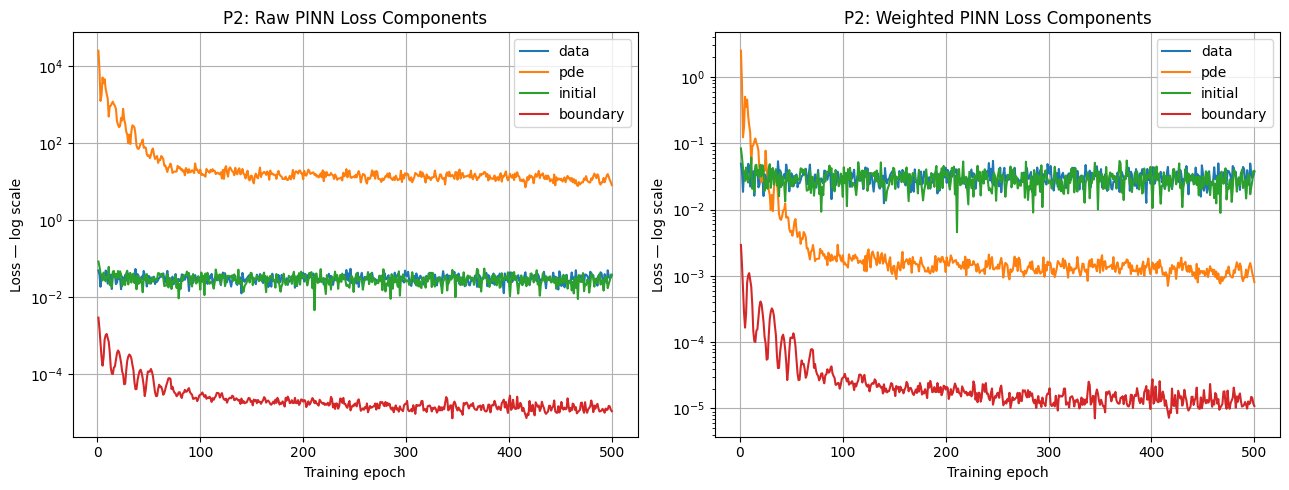


PINN training completed.
Selected checkpoint epoch: 500
Best sampled validation MSE: 0.03262462094426155
Training time: 10.92 seconds
Existing FNO remains unchanged.


In [57]:
# @title Train the Physics-Informed Space-Time Model

import copy
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

# Reproducible restart from the saved initial weights
pinn_model.load_state_dict(pinn_initial_weights)
torch.manual_seed(123)

pinn_optimizer = torch.optim.Adam(
    pinn_model.parameters(), lr=0.001
)

pinn_weights = {
    "data": 1.0,
    "pde": 1e-4,
    "initial": 1.0,
    "boundary": 1.0
}

pinn_epochs = 500
pinn_history = {name: [] for name in pinn_weights}
pinn_validation_history = []
pinn_validation_epochs = []

# Fixed validation points, separate from training data
validation_rng = np.random.default_rng(123)

validation_examples = validation_rng.integers(
    len(trajectory_val_controls), size=2048
)
validation_times = validation_rng.integers(
    len(trajectory_times), size=2048
)
validation_positions = validation_rng.integers(
    len(x), size=2048
)

validation_x = torch.tensor(
    x[validation_positions, None], dtype=torch.float32
)
validation_t = torch.tensor(
    trajectory_times[validation_times, None],
    dtype=torch.float32
)
validation_controls_tensor = torch.tensor(
    trajectory_val_controls[validation_examples],
    dtype=torch.float32
)

validation_complex = trajectory_val_waves[
    validation_examples,
    validation_times,
    validation_positions
]

validation_targets = torch.tensor(
    np.stack(
        [validation_complex.real, validation_complex.imag],
        axis=-1
    ),
    dtype=torch.float32
)

best_validation_mse = float("inf")
best_pinn_weights = None
best_pinn_epoch = None

start = time.perf_counter()

for epoch in range(1, pinn_epochs + 1):
    pinn_model.train()
    pinn_optimizer.zero_grad(set_to_none=True)

    losses = pinn_loss_components(pinn_model)

    total_loss = sum(
        pinn_weights[name] * value
        for name, value in losses.items()
    )

    if not torch.isfinite(total_loss).item():
        raise RuntimeError("Non-finite loss; training stopped.")

    total_loss.backward()
    pinn_optimizer.step()

    for name, value in losses.items():
        pinn_history[name].append(value.item())

    if epoch == 1 or epoch % 50 == 0:
        pinn_model.eval()

        with torch.no_grad():
            validation_prediction = pinn_model(
                validation_x,
                validation_t,
                validation_controls_tensor
            )

            validation_mse = torch.mean(
                (validation_prediction - validation_targets)**2
            ).item()

        pinn_validation_epochs.append(epoch)
        pinn_validation_history.append(validation_mse)

        if validation_mse < best_validation_mse:
            best_validation_mse = validation_mse
            best_pinn_weights = copy.deepcopy(
                pinn_model.state_dict()
            )
            best_pinn_epoch = epoch

        print(
            f"Epoch {epoch}/{pinn_epochs} | "
            f"data={losses['data'].item():.3e} | "
            f"pde={losses['pde'].item():.3e} | "
            f"ic={losses['initial'].item():.3e} | "
            f"bc={losses['boundary'].item():.3e} | "
            f"validation MSE={validation_mse:.3e}"
        )

pinn_training_time = time.perf_counter() - start

# Retain the checkpoint selected using validation data
pinn_model.load_state_dict(best_pinn_weights)
pinn_model.eval()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
epoch_axis = np.arange(1, pinn_epochs + 1)

for name, values in pinn_history.items():
    values = np.asarray(values)

    axes[0].semilogy(
        epoch_axis,
        np.maximum(values, 1e-16),
        label=name
    )

    axes[1].semilogy(
        epoch_axis,
        np.maximum(pinn_weights[name] * values, 1e-16),
        label=name
    )

axes[0].set_title("P2: Raw PINN Loss Components")
axes[1].set_title("P2: Weighted PINN Loss Components")

for axis in axes:
    axis.set_xlabel("Training epoch")
    axis.set_ylabel("Loss — log scale")
    axis.legend()
    axis.grid(True)

plt.tight_layout()
plt.savefig("P2_PINN_loss_components.png", dpi=200)
plt.show()

print("\nPINN training completed.")
print("Selected checkpoint epoch:", best_pinn_epoch)
print("Best sampled validation MSE:", best_validation_mse)
print("Training time:", round(pinn_training_time, 2), "seconds")
print("Existing FNO remains unchanged.")

Validation 1: space-time wave error=98.99% | predicted probability range=0.0001 to 0.0227
Validation 2: space-time wave error=99.80% | predicted probability range=0.0001 to 0.0050
Validation 3: space-time wave error=99.63% | predicted probability range=0.0001 to 0.0056
Validation 4: space-time wave error=99.50% | predicted probability range=0.0000 to 0.0147
Validation 5: space-time wave error=99.79% | predicted probability range=0.0000 to 0.0042

Mean space-time validation error: 99.54%


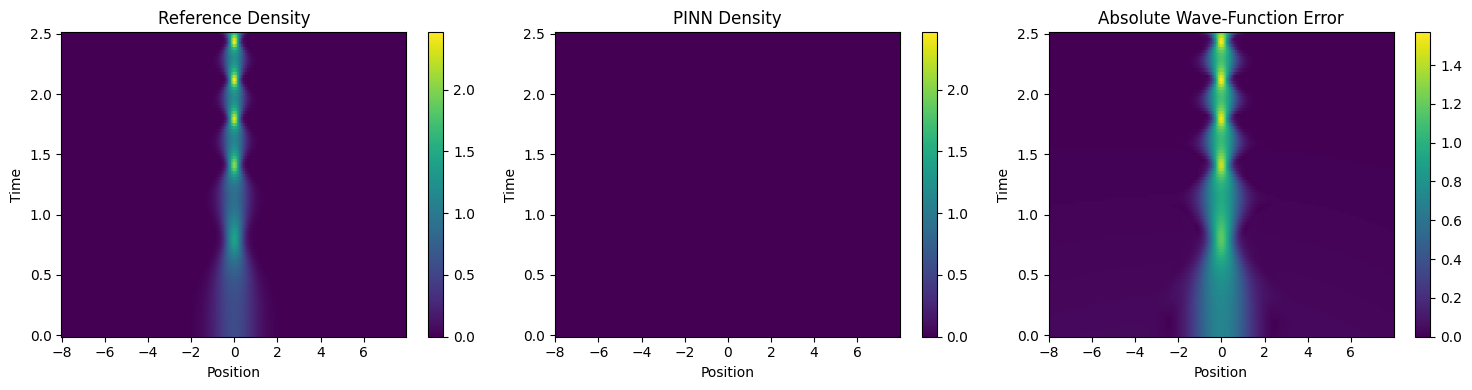

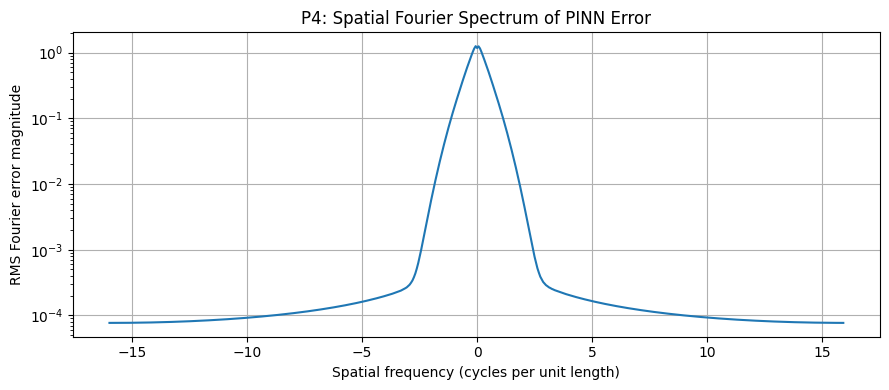

In [58]:
# @title Evaluate PINN Space-Time Predictions

import numpy as np
import torch
import matplotlib.pyplot as plt

pinn_model.eval()

grid_x, grid_t = np.meshgrid(x, trajectory_times)

flat_x = torch.tensor(
    grid_x.reshape(-1, 1), dtype=torch.float32
)
flat_t = torch.tensor(
    grid_t.reshape(-1, 1), dtype=torch.float32
)

pinn_validation_errors = []
pinn_validation_predictions = []

with torch.no_grad():
    for case, coefficients in enumerate(trajectory_val_controls):
        prediction_batches = []

        for start in range(0, len(flat_x), 4096):
            stop = start + 4096
            batch_x = flat_x[start:stop]
            batch_t = flat_t[start:stop]

            batch_controls = torch.tensor(
                coefficients, dtype=torch.float32
            ).reshape(1, 3).repeat(len(batch_x), 1)

            prediction_batches.append(
                pinn_model(
                    batch_x, batch_t, batch_controls
                ).cpu().numpy()
            )

        prediction = np.concatenate(prediction_batches)

        predicted_wave = (
            prediction[:, 0] + 1j * prediction[:, 1]
        ).reshape(grid_x.shape)

        actual_wave = trajectory_val_waves[case]

        relative_error = (
            np.linalg.norm(predicted_wave - actual_wave)
            / np.linalg.norm(actual_wave)
        )

        probability = (
            np.sum(np.abs(predicted_wave)**2, axis=1) * dx
        )

        pinn_validation_errors.append(relative_error)
        pinn_validation_predictions.append(predicted_wave)

        print(
            f"Validation {case + 1}: "
            f"space-time wave error={100 * relative_error:.2f}% | "
            f"predicted probability range="
            f"{probability.min():.4f} to {probability.max():.4f}"
        )

print(
    "\nMean space-time validation error:",
    f"{100 * np.mean(pinn_validation_errors):.2f}%"
)

# P4: inspect the first validation case
reference = trajectory_val_waves[0]
prediction = pinn_validation_predictions[0]
wave_error = prediction - reference

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

fields = [
    np.abs(reference)**2,
    np.abs(prediction)**2,
    np.abs(wave_error)
]

titles = [
    "Reference Density",
    "PINN Density",
    "Absolute Wave-Function Error"
]

# Same density color scale for reference and prediction
density_max = max(fields[0].max(), fields[1].max())

for i, (axis, field, title) in enumerate(zip(axes, fields, titles)):
    plot = axis.pcolormesh(
        x,
        trajectory_times,
        field,
        shading="auto",
        cmap="viridis",
        vmin=0,
        vmax=density_max if i < 2 else None
    )
    axis.set_title(title)
    axis.set_xlabel("Position")
    axis.set_ylabel("Time")
    fig.colorbar(plot, ax=axis)

plt.tight_layout()
plt.savefig("P4_PINN_spacetime_error.png", dpi=200)
plt.show()

# Fourier spectrum of the ERROR, averaged over saved times
frequencies = np.fft.fftshift(
    np.fft.fftfreq(len(x), d=dx)
)

error_fft = dx * np.fft.fft(wave_error, axis=1)

error_spectrum = np.fft.fftshift(
    np.sqrt(np.mean(np.abs(error_fft)**2, axis=0))
)

plt.figure(figsize=(9, 4))
plt.semilogy(
    frequencies,
    np.maximum(error_spectrum, 1e-16)
)
plt.xlabel("Spatial frequency (cycles per unit length)")
plt.ylabel("RMS Fourier error magnitude")
plt.title("P4: Spatial Fourier Spectrum of PINN Error")
plt.grid(True)
plt.tight_layout()
plt.savefig("P4_PINN_error_spectrum.png", dpi=200)
plt.show()

Physics-informed model failure

The PINN’s PDE and boundary losses decreased during training, but its mean relative space–time validation error remained 99.54%. Predicted total probabilities stayed below 0.023 instead of the reference value of 1.
These results indicate near-zero predictions. The zero function satisfies the homogeneous GPE and periodic boundary conditions, illustrating why small physics losses alone do not guarantee an accurate solution. This experiment does not yet establish why training favored this solution.

In [59]:
# @title Controlled Comparison: Data-Only Space-Time Model

import copy
import time
import numpy as np
import torch

# Same architecture and starting weights as the PINN
data_only_model = BECSpaceTimeModel(final_time=T)
data_only_model.load_state_dict(pinn_initial_weights)

torch.manual_seed(123)

data_only_optimizer = torch.optim.Adam(
    data_only_model.parameters(), lr=0.001
)

data_only_history = []
data_only_validation_history = []
best_data_only_mse = float("inf")
best_data_only_weights = None
best_data_only_epoch = None

start = time.perf_counter()

for epoch in range(1, pinn_epochs + 1):
    data_only_model.train()
    data_only_optimizer.zero_grad(set_to_none=True)

    # Same number of sampled data points per update as the PINN
    example_ids = torch.randint(len(pinn_controls), (256,))
    time_ids = torch.randint(len(pinn_t_grid), (256,))
    space_ids = torch.randint(len(pinn_x_grid), (256,))

    prediction = data_only_model(
        pinn_x_grid[space_ids, None],
        pinn_t_grid[time_ids, None],
        pinn_controls[example_ids]
    )

    target = pinn_reference[
        example_ids, time_ids, space_ids
    ]

    loss = torch.mean((prediction - target)**2)

    loss.backward()
    data_only_optimizer.step()

    data_only_history.append(loss.item())

    if epoch == 1 or epoch % 50 == 0:
        data_only_model.eval()

        with torch.no_grad():
            validation_prediction = data_only_model(
                validation_x,
                validation_t,
                validation_controls_tensor
            )

            validation_mse = torch.mean(
                (validation_prediction - validation_targets)**2
            ).item()

        data_only_validation_history.append(validation_mse)

        if validation_mse < best_data_only_mse:
            best_data_only_mse = validation_mse
            best_data_only_weights = copy.deepcopy(
                data_only_model.state_dict()
            )
            best_data_only_epoch = epoch

        print(
            f"Epoch {epoch}/{pinn_epochs} | "
            f"data MSE={loss.item():.3e} | "
            f"validation MSE={validation_mse:.3e}"
        )

data_only_training_time = time.perf_counter() - start

data_only_model.load_state_dict(best_data_only_weights)
data_only_model.eval()

# Evaluate on the same full validation trajectories as the PINN
data_only_errors = []

with torch.no_grad():
    for case, coefficients in enumerate(trajectory_val_controls):
        batches = []

        for start in range(0, len(flat_x), 4096):
            batch_x = flat_x[start:start + 4096]
            batch_t = flat_t[start:start + 4096]

            batch_controls = torch.tensor(
                coefficients, dtype=torch.float32
            ).reshape(1, 3).repeat(len(batch_x), 1)

            batches.append(
                data_only_model(
                    batch_x, batch_t, batch_controls
                ).cpu().numpy()
            )

        prediction = np.concatenate(batches)

        predicted_wave = (
            prediction[:, 0] + 1j * prediction[:, 1]
        ).reshape(grid_x.shape)

        actual_wave = trajectory_val_waves[case]

        error = (
            np.linalg.norm(predicted_wave - actual_wave)
            / np.linalg.norm(actual_wave)
        )

        probability = (
            np.sum(np.abs(predicted_wave)**2, axis=1) * dx
        )

        data_only_errors.append(error)

        print(
            f"\nValidation {case + 1}: "
            f"wave error={100 * error:.2f}% | "
            f"probability range="
            f"{probability.min():.4f} to {probability.max():.4f}"
        )

print("\nCONTROLLED COMPARISON")
print(
    "Physics-informed mean space-time error:",
    f"{100 * np.mean(pinn_validation_errors):.2f}%"
)
print(
    "Data-only mean space-time error:",
    f"{100 * np.mean(data_only_errors):.2f}%"
)
print("Data-only selected epoch:", best_data_only_epoch)
print(
    "Data-only training time:",
    round(data_only_training_time, 2),
    "seconds"
)

Epoch 1/500 | data MSE=4.914e-02 | validation MSE=3.639e-02
Epoch 50/500 | data MSE=2.977e-02 | validation MSE=3.250e-02
Epoch 100/500 | data MSE=2.837e-02 | validation MSE=3.236e-02
Epoch 150/500 | data MSE=3.088e-02 | validation MSE=3.262e-02
Epoch 200/500 | data MSE=3.957e-02 | validation MSE=3.232e-02
Epoch 250/500 | data MSE=2.408e-02 | validation MSE=3.243e-02
Epoch 300/500 | data MSE=3.635e-02 | validation MSE=3.247e-02
Epoch 350/500 | data MSE=2.112e-02 | validation MSE=3.211e-02
Epoch 400/500 | data MSE=2.552e-02 | validation MSE=3.194e-02
Epoch 450/500 | data MSE=2.369e-02 | validation MSE=3.169e-02
Epoch 500/500 | data MSE=3.037e-02 | validation MSE=3.124e-02

Validation 1: wave error=94.58% | probability range=0.0040 to 0.2193

Validation 2: wave error=100.03% | probability range=0.0055 to 0.1373

Validation 3: wave error=97.16% | probability range=0.0045 to 0.2522

Validation 4: wave error=96.66% | probability range=0.0056 to 0.1934

Validation 5: wave error=98.53% | proba

Controlled comparison: physics-informed versus data-only training
We trained the same space–time architecture from identical initial weights using either physics-informed losses or data loss alone. Both experiments used the same training controls, learning rate, number of updates, and validation checkpoint rule.

Mean relative space–time validation error was 99.54% for physics-informed training and 97.39% for data-only training. Both models substantially underestimated total probability.
Removing the physics losses did not restore accurate predictions. Therefore, this experiment does not isolate physics-loss imbalance as the sole cause. Further checks are needed to distinguish training limitations, representation limitations, and sampling effects.

In [60]:
# @title Check Whether the Space-Time Models Fit Their Training Data

import numpy as np
import torch

def evaluate_training_trajectories(network):
    network.eval()
    errors = []
    mean_probabilities = []

    with torch.no_grad():
        for case, coefficients in enumerate(trajectory_train_controls):
            batches = []

            for start in range(0, len(flat_x), 4096):
                batch_x = flat_x[start:start + 4096]
                batch_t = flat_t[start:start + 4096]

                batch_controls = torch.tensor(
                    coefficients, dtype=torch.float32
                ).reshape(1, 3).repeat(len(batch_x), 1)

                batches.append(
                    network(
                        batch_x, batch_t, batch_controls
                    ).cpu().numpy()
                )

            prediction = np.concatenate(batches)

            predicted_wave = (
                prediction[:, 0] + 1j * prediction[:, 1]
            ).reshape(grid_x.shape)

            reference_wave = trajectory_train_waves[case]

            error = (
                np.linalg.norm(predicted_wave - reference_wave)
                / np.linalg.norm(reference_wave)
            )

            probabilities = (
                np.sum(np.abs(predicted_wave)**2, axis=1) * dx
            )

            errors.append(error)
            mean_probabilities.append(probabilities.mean())

    return np.mean(errors), np.mean(mean_probabilities)


print("Evaluating all 20 training trajectories...")

pinn_train_error, pinn_train_probability = (
    evaluate_training_trajectories(pinn_model)
)

data_only_train_error, data_only_train_probability = (
    evaluate_training_trajectories(data_only_model)
)

print("\nPHYSICS-INFORMED MODEL")
print(f"Training wave error: {100 * pinn_train_error:.2f}%")
print(
    "Validation wave error:",
    f"{100 * np.mean(pinn_validation_errors):.2f}%"
)
print(f"Mean training probability: {pinn_train_probability:.4f}")

print("\nDATA-ONLY MODEL")
print(f"Training wave error: {100 * data_only_train_error:.2f}%")
print(
    "Validation wave error:",
    f"{100 * np.mean(data_only_errors):.2f}%"
)
print(f"Mean training probability: {data_only_train_probability:.4f}")

print("\nReference total probability is approximately 1.")
print("No model weights were changed.")

Evaluating all 20 training trajectories...

PHYSICS-INFORMED MODEL
Training wave error: 99.45%
Validation wave error: 99.54%
Mean training probability: 0.0023

DATA-ONLY MODEL
Training wave error: 96.64%
Validation wave error: 97.39%
Mean training probability: 0.0602

Reference total probability is approximately 1.
No model weights were changed.



TIME HORIZON: 0.1
  Data only: epoch 250/500
  Data only: epoch 500/500
  Validation wave error: 9.09%
  Physics-informed: epoch 250/500
  Physics-informed: epoch 500/500
  Validation wave error: 10.81%

TIME HORIZON: 0.5
  Data only: epoch 250/500
  Data only: epoch 500/500
  Validation wave error: 43.06%
  Physics-informed: epoch 250/500
  Physics-informed: epoch 500/500
  Validation wave error: 72.61%

TIME HORIZON: 1.0
  Data only: epoch 250/500
  Data only: epoch 500/500
  Validation wave error: 52.80%
  Physics-informed: epoch 250/500
  Physics-informed: epoch 500/500
  Validation wave error: 95.85%

TIME HORIZON: 2.5
  Data only: epoch 250/500
  Data only: epoch 500/500
  Validation wave error: 97.30%
  Physics-informed: epoch 250/500
  Physics-informed: epoch 500/500
  Validation wave error: 99.52%

P3: TIME-HORIZON RESULTS
 Horizon         Approach  Validation wave error (%)  Mean predicted probability  Training time (s)  Five-trajectory evaluation time (s)
     0.1        Da

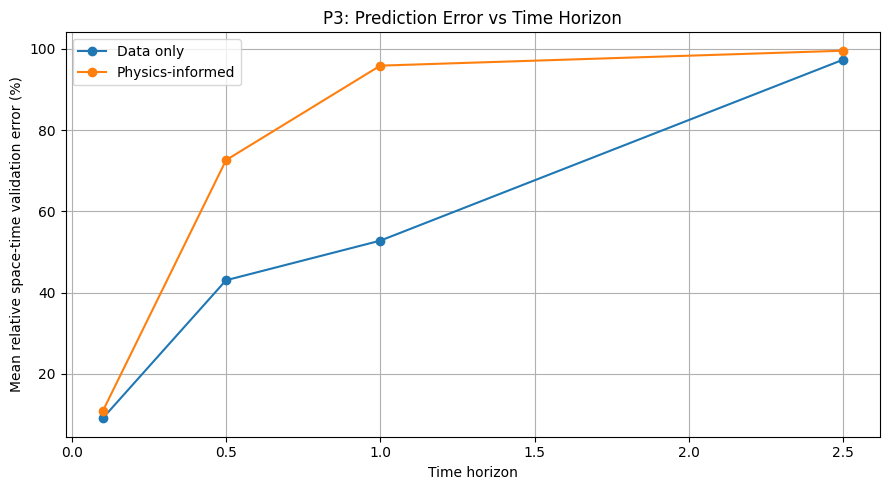


Existing FNO and PINN models remain unchanged.
Results use final checkpoints after 500 updates.
Errors are evaluated on the same five validation controls.


In [63]:
# @title P3: Difficulty Sweep — Increasing Time Horizon

import numpy as np
import pandas as pd
import torch
import time
import matplotlib.pyplot as plt

horizons = [0.1, 0.5, 1.0, 2.5]
sweep_epochs = 500
sweep_rows = []
sweep_loss_histories = {}

# Separate generator gives both models identical data batches
def sample_sweep_data(horizon, generator):
    eligible_times = torch.where(
        pinn_t_grid <= horizon + 1e-6
    )[0]

    example_ids = torch.randint(
        len(pinn_controls), (256,), generator=generator
    )
    time_choices = torch.randint(
        len(eligible_times), (256,), generator=generator
    )
    space_ids = torch.randint(
        len(pinn_x_grid), (256,), generator=generator
    )

    time_ids = eligible_times[time_choices]

    return (
        pinn_x_grid[space_ids, None],
        pinn_t_grid[time_ids, None],
        pinn_controls[example_ids],
        pinn_reference[example_ids, time_ids, space_ids]
    )


def sweep_physics_losses(net, horizon):
    # PDE points restricted to the current time horizon
    xr = (-8 + 16 * torch.rand(256, 1)).requires_grad_()
    tr = (horizon * torch.rand(256, 1)).requires_grad_()

    ids = torch.randint(len(pinn_controls), (256,))
    controls = pinn_controls[ids]

    prediction = net(xr, tr, controls)
    real = prediction[:, 0:1]
    imag = prediction[:, 1:2]

    real_t = derivative(real, tr)
    imag_t = derivative(imag, tr)
    real_xx = derivative(derivative(real, xr), xr)
    imag_xx = derivative(derivative(imag, xr), xr)

    modes = torch.arange(1, 4, dtype=xr.dtype)[None, :]

    # T remains 2.5: do not compress the control schedule
    control = (
        u0 + (uT - u0) * tr / T
        + torch.sum(
            controls * torch.sin(modes * torch.pi * tr / T),
            dim=1,
            keepdim=True
        )
    )

    potential = 0.5 * control * xr**2
    density = real**2 + imag**2

    residual_real = (
        -imag_t + 0.5 * real_xx
        - potential * real - density * real
    )
    residual_imag = (
        real_t + 0.5 * imag_xx
        - potential * imag - density * imag
    )

    pde_loss = torch.mean(
        residual_real**2 + residual_imag**2
    )

    # Initial condition
    xi = -8 + 16 * torch.rand(64, 1)
    ids = torch.randint(len(pinn_controls), (64,))

    initial_prediction = net(
        xi, torch.zeros_like(xi), pinn_controls[ids]
    )

    initial_real = (
        pinn_initial_scale * torch.exp(-xi**2 / 2)
    )

    initial_target = torch.cat(
        [initial_real, torch.zeros_like(initial_real)],
        dim=1
    )

    initial_loss = torch.mean(
        (initial_prediction - initial_target)**2
    )

    # Periodic values and derivatives
    tb = horizon * torch.rand(64, 1)
    ids = torch.randint(len(pinn_controls), (64,))
    controls = pinn_controls[ids]

    left = torch.full((64, 1), -8.0, requires_grad=True)
    right = torch.full((64, 1), 8.0, requires_grad=True)

    left_prediction = net(left, tb, controls)
    right_prediction = net(right, tb, controls)

    left_dx = torch.cat([
        derivative(left_prediction[:, 0:1], left),
        derivative(left_prediction[:, 1:2], left)
    ], dim=1)

    right_dx = torch.cat([
        derivative(right_prediction[:, 0:1], right),
        derivative(right_prediction[:, 1:2], right)
    ], dim=1)

    boundary_loss = (
        torch.mean((left_prediction - right_prediction)**2)
        + torch.mean((left_dx - right_dx)**2)
    )

    return pde_loss, initial_loss, boundary_loss


def evaluate_sweep_model(net, horizon):
    mask = trajectory_times <= horizon + 1e-6
    selected_times = trajectory_times[mask]

    xx, tt = np.meshgrid(x, selected_times)

    query_x = torch.tensor(
        xx.reshape(-1, 1), dtype=torch.float32
    )
    query_t = torch.tensor(
        tt.reshape(-1, 1), dtype=torch.float32
    )

    errors = []
    probabilities = []

    net.eval()

    with torch.no_grad():
        for case, coefficients in enumerate(trajectory_val_controls):
            batches = []

            for start in range(0, len(query_x), 4096):
                batch_x = query_x[start:start + 4096]
                batch_t = query_t[start:start + 4096]

                controls = torch.tensor(
                    coefficients, dtype=torch.float32
                )[None, :].repeat(len(batch_x), 1)

                batches.append(
                    net(batch_x, batch_t, controls).numpy()
                )

            prediction = np.concatenate(batches)

            predicted_wave = (
                prediction[:, 0] + 1j * prediction[:, 1]
            ).reshape(xx.shape)

            reference = trajectory_val_waves[case, mask]

            errors.append(
                np.linalg.norm(predicted_wave - reference)
                / np.linalg.norm(reference)
            )

            probabilities.append(
                np.mean(
                    np.sum(np.abs(predicted_wave)**2, axis=1) * dx
                )
            )

    return 100 * np.mean(errors), np.mean(probabilities)


for horizon in horizons:
    print(f"\nTIME HORIZON: {horizon}")

    for approach in ["Data only", "Physics-informed"]:
        # Same weights and input scaling in every experiment
        network = BECSpaceTimeModel(final_time=T)
        network.load_state_dict(pinn_initial_weights)

        optimizer = torch.optim.Adam(
            network.parameters(), lr=0.001
        )

        data_generator = torch.Generator().manual_seed(456)
        torch.manual_seed(789)

        history = {
            "data": [],
            "pde": [],
            "initial": [],
            "boundary": []
        }

        start = time.perf_counter()

        for epoch in range(1, sweep_epochs + 1):
            network.train()
            optimizer.zero_grad(set_to_none=True)

            batch_x, batch_t, controls, targets = (
                sample_sweep_data(horizon, data_generator)
            )

            prediction = network(batch_x, batch_t, controls)
            data_loss = torch.mean((prediction - targets)**2)
            history["data"].append(data_loss.item())

            total = data_loss

            if approach == "Physics-informed":
                pde, initial, boundary = (
                    sweep_physics_losses(network, horizon)
                )

                total = total + 1e-4 * pde + initial + boundary

                history["pde"].append(pde.item())
                history["initial"].append(initial.item())
                history["boundary"].append(boundary.item())

            if not torch.isfinite(total).item():
                raise RuntimeError("Non-finite loss in horizon sweep.")

            total.backward()
            optimizer.step()

            if epoch % 250 == 0:
                print(f"  {approach}: epoch {epoch}/{sweep_epochs}")

        training_seconds = time.perf_counter() - start

        # Evaluate the final checkpoint after exactly 500 updates
        start = time.perf_counter()
        error, probability = evaluate_sweep_model(network, horizon)
        evaluation_seconds = time.perf_counter() - start

        sweep_rows.append({
            "Horizon": horizon,
            "Approach": approach,
            "Validation wave error (%)": error,
            "Mean predicted probability": probability,
            "Training time (s)": training_seconds,
            "Five-trajectory evaluation time (s)": evaluation_seconds
        })

        sweep_loss_histories[(horizon, approach)] = history

        print(f"  Validation wave error: {error:.2f}%")


horizon_results = pd.DataFrame(sweep_rows)
horizon_results.to_csv("P3_time_horizon_results.csv", index=False)

print("\nP3: TIME-HORIZON RESULTS")
print(horizon_results.round(4).to_string(index=False))

plt.figure(figsize=(9, 5))

for approach in ["Data only", "Physics-informed"]:
    rows = horizon_results[
        horizon_results["Approach"] == approach
    ]

    plt.plot(
        rows["Horizon"],
        rows["Validation wave error (%)"],
        marker="o",
        label=approach
    )

plt.xlabel("Time horizon")
plt.ylabel("Mean relative space-time validation error (%)")
plt.title("P3: Prediction Error vs Time Horizon")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("P3_time_horizon_sweep.png", dpi=200)
plt.show()

print("\nExisting FNO and PINN models remain unchanged.")
print("Results use final checkpoints after 500 updates.")
print("Errors are evaluated on the same five validation controls.")

P3: Effect of time horizon
We used time horizon as the difficulty knob, testing 0.1, 0.5, 1.0, and 2.5 dimensionless time units. Each experiment used the same architecture, initial weights, training controls, learning rate, and 500 updates. Both approaches received identical sampled data points. The control schedule was unchanged; longer horizons included more of the same evolution.

Data-only validation error increased from 9.09% to 97.30%, while physics-informed error increased from 10.81% to 99.52%. The physics-informed model’s mean predicted probability decreased from 0.9508 to 0.0023.
These results identify increasing trajectory duration as a contributor to failure under the tested training budget. The physics-informed formulation performed worse at intermediate horizons and approached the zero solution at long horizons. However, this experiment does not isolate temporal oscillations, sampling density, and optimization difficulty from one another. It does not prove a causality failure or that longer training would be ineffective.
The conclusion is limited to one initialization, five validation controls, and the chosen loss weights.

------------------------------------------------------------------------------
This code creates a graph comparing the total time needed to make up to 150 predictions using the traditional BEC solver and the AI model. The AI’s total includes generating its training data and training it, plus prediction time. The dashed line marks the break-even point, where the AI begins saving time overall. Finally, it displays the graph and saves it as P5_runtime_comparison.png for your report.
These lines are estimates based on your previously measured average runtimes; the code does not run new simulations.

Create your required runtime graph




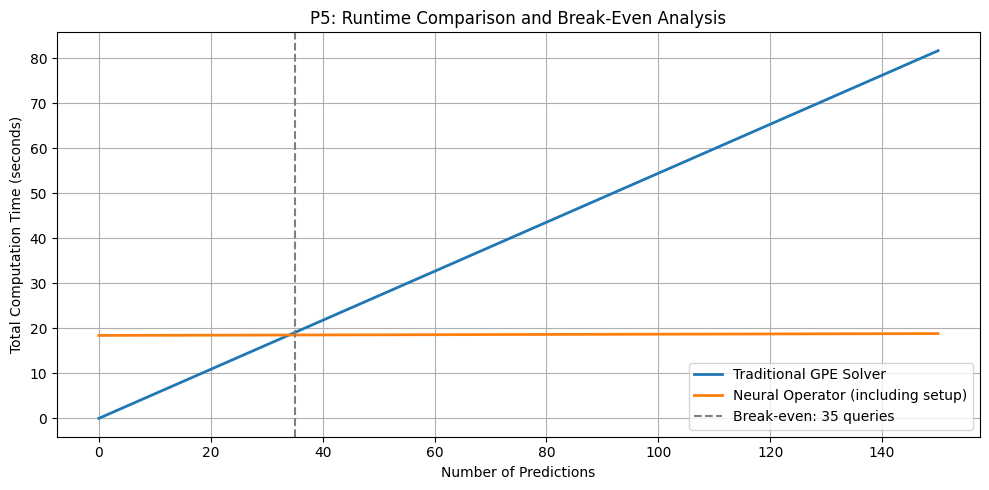

P5 graph saved successfully!


In [27]:
# @title
print("Create your required runtime graph\n\n")
# P5: Runtime comparison and break-even graph

import numpy as np
import matplotlib.pyplot as plt

queries = np.arange(0, 151)

# Total computation time for each approach
traditional_total = queries * traditional_average
ai_total = total_ai_setup_time + queries * ai_average

plt.figure(figsize=(10, 5))

plt.plot(
    queries, traditional_total,
    label="Traditional GPE Solver",
    linewidth=2
)

plt.plot(
    queries, ai_total,
    label="Neural Operator (including setup)",
    linewidth=2
)

plt.axvline(
    break_even,
    color="gray",
    linestyle="--",
    label=f"Break-even: {int(break_even)} queries"
)

plt.xlabel("Number of Predictions")
plt.ylabel("Total Computation Time (seconds)")
plt.title("P5: Runtime Comparison and Break-Even Analysis")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("P5_runtime_comparison.png", dpi=300)
plt.show()

print("P5 graph saved successfully!")



-------------------------------------------------------------------------------
This code plots the initial and final BEC probability densities from the traditional GPE solver, showing how the density changes during the simulation. It displays the graph and saves it as P1_baseline_simulation.png for the report.

Save P1: Baseline GPE simulation


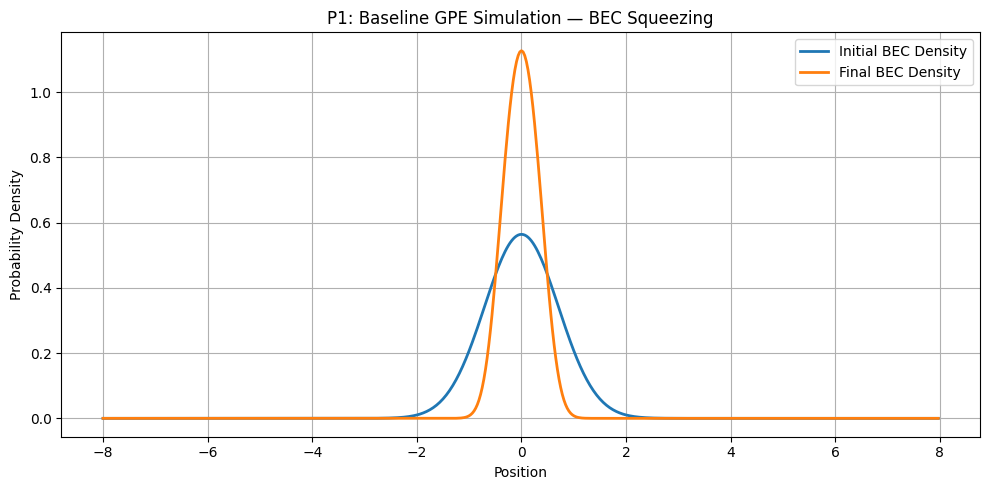

P1 graph saved successfully!


In [31]:
# @title
print("Save P1: Baseline GPE simulation")
# P1: Baseline GPE simulation

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    x, initial_density,
    label="Initial BEC Density",
    linewidth=2
)

plt.plot(
    x, final_density,
    label="Final BEC Density",
    linewidth=2
)

plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("P1: Baseline GPE Simulation — BEC Squeezing")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("P1_baseline_simulation.png", dpi=300)
plt.show()

print("P1 graph saved successfully!")


P1 graph shows how the Bose–Einstein condensate changes when we increase the trapping strength.

Blue line: The initial condensate has a wider probability distribution.

Orange line: The final condensate is narrower and more concentrated around the center.

Result: The condensate's width decreased by approximately 52.56% in our baseline simulation. This demonstrates that our traditional GPE solver successfully simulated the squeezing behavior. How to explain it in your presentation Our first experiment used a traditional numerical solver to simulate Bose–Einstein condensate squeezing. As the trapping strength increased, the condensate became narrower and more concentrated near the center. We measured a width reduction of approximately 52.56%. This simulation established the baseline for our later optimization and AI experiments.

----------------------------------------------------------------------------
This code uses the trained AI model with SciPy’s optimizer to search for control settings predicted to produce a wave close to the target. It then checks those settings with the traditional GPE solver and compares the resulting density error with your previous traditional optimization result. This tests whether the AI-selected controls work when applied to the actual simulation.



In [41]:
# @title Matched Traditional vs AI Control Comparison

import numpy as np
import torch
import time
from scipy.optimize import minimize

model.eval()

# Shared objective: normalized infidelity + coefficient penalty
def comparison_objective(wave, coefficients):
    target_mass = np.sum(np.abs(target_wave)**2) * dx
    wave_mass = np.sum(np.abs(wave)**2) * dx

    if wave_mass < 1e-12:
        return 1e6

    overlap = np.sum(np.conj(target_wave) * wave) * dx
    fidelity = np.abs(overlap)**2 / (target_mass * wave_mass)
    infidelity = 1.0 - np.clip(fidelity, 0.0, 1.0)

    penalty = 1e-5 * np.sum(np.asarray(coefficients)**2)

    return float(infidelity + penalty)


# Objective evaluated using the traditional solver
def traditional_comparison_objective(coefficients):
    wave = simulate_smooth(coefficients)
    return comparison_objective(wave, coefficients)


# Objective evaluated using the trained AI model
def ai_comparison_objective(coefficients):
    parameter = next(model.parameters())

    controls = torch.as_tensor(
        np.asarray(coefficients).reshape(1, 3),
        dtype=parameter.dtype,
        device=parameter.device
    )

    with torch.no_grad():
        prediction = model(controls)[0].detach().cpu().numpy()

    wave = prediction[:, 0] + 1j * prediction[:, 1]

    return comparison_objective(wave, coefficients)


# Match bounds, starting point, optimizer, and stopping settings
bounds = [(-20.0, 20.0)] * 3
initial_guess = np.zeros(3)

search_options = {
    "maxiter": 30,
    "xtol": 1e-3,
    "ftol": 1e-6
}

print("Running traditional optimization...")

start = time.perf_counter()

traditional_comparison_result = minimize(
    traditional_comparison_objective,
    initial_guess.copy(),
    method="Powell",
    bounds=bounds,
    options=search_options.copy()
)

traditional_search_time = time.perf_counter() - start

print("Running AI-assisted optimization...")

start = time.perf_counter()

ai_optimization_result = minimize(
    ai_comparison_objective,
    initial_guess.copy(),
    method="Powell",
    bounds=bounds,
    options=search_options.copy()
)

ai_search_time = time.perf_counter() - start

# Verify both sets of controls using the traditional solver
traditional_coefficients = traditional_comparison_result.x
ai_coefficients = ai_optimization_result.x

traditional_verified_wave = simulate_smooth(traditional_coefficients)
ai_verified_wave = simulate_smooth(ai_coefficients)

# Names retained for the following comparison plot
new_optimized_density = np.abs(traditional_verified_wave)**2
ai_verified_density = np.abs(ai_verified_wave)**2

target_density = np.abs(target_wave)**2

traditional_error = np.sqrt(
    np.sum((new_optimized_density - target_density)**2) * dx
)

verified_error = np.sqrt(
    np.sum((ai_verified_density - target_density)**2) * dx
)

traditional_verified_objective = comparison_objective(
    traditional_verified_wave, traditional_coefficients
)

ai_verified_objective = comparison_objective(
    ai_verified_wave, ai_coefficients
)

print("\n" + "=" * 55)
print("MATCHED TRADITIONAL VS AI COMPARISON")
print("=" * 55)

print("\nTraditional control coefficients:")
print(traditional_coefficients)

print("\nAI-selected control coefficients:")
print(ai_coefficients)

print("\nSolver-verified density L2 error:")
print(f"Traditional: {traditional_error:.6f}")
print(f"AI-assisted: {verified_error:.6f}")

print("\nSolver-verified objective, including coefficient penalty:")
print(f"Traditional: {traditional_verified_objective:.6f}")
print(f"AI-assisted: {ai_verified_objective:.6f}")

print("\nAI-predicted objective:")
print(f"{ai_optimization_result.fun:.6f}")

print("\nOptimization time, excluding final verification:")
print(f"Traditional: {traditional_search_time:.2f} seconds")
print(f"AI-assisted: {ai_search_time:.2f} seconds")

print("\nObjective evaluations:")
print("Traditional:", traditional_comparison_result.nfev)
print("AI-assisted:", ai_optimization_result.nfev)

print("\nOptimizer success:")
print("Traditional:", traditional_comparison_result.success)
print("AI-assisted:", ai_optimization_result.success)

print("\nOptimizer messages:")
print("Traditional:", traditional_comparison_result.message)
print("AI-assisted:", ai_optimization_result.message)

print("\nTimes exclude AI data generation and training.")
print("Coefficient bounds match the AI training range [-20, 20].")
print("These bounds do not guarantee bounds on the control u(t).")
print("=" * 55)

Running traditional optimization...
Running AI-assisted optimization...

MATCHED TRADITIONAL VS AI COMPARISON

Traditional control coefficients:
[-19.99999533  -3.95512917   0.985838  ]

AI-selected control coefficients:
[ 7.2113497  -9.69234177  3.50331095]

Solver-verified density L2 error:
Traditional: 0.253400
AI-assisted: 0.254834

Solver-verified objective, including coefficient penalty:
Traditional: 0.052612
AI-assisted: 0.122382

AI-predicted objective:
0.081621

Optimization time, excluding final verification:
Traditional: 121.88 seconds
AI-assisted: 0.21 seconds

Objective evaluations:
Traditional: 323
AI-assisted: 104

Optimizer success:
Traditional: True
AI-assisted: True

Optimizer messages:
Traditional: Optimization terminated successfully.
AI-assisted: Optimization terminated successfully.

Times exclude AI data generation and training.
Coefficient bounds match the AI training range [-20, 20].
These bounds do not guarantee bounds on the control u(t).


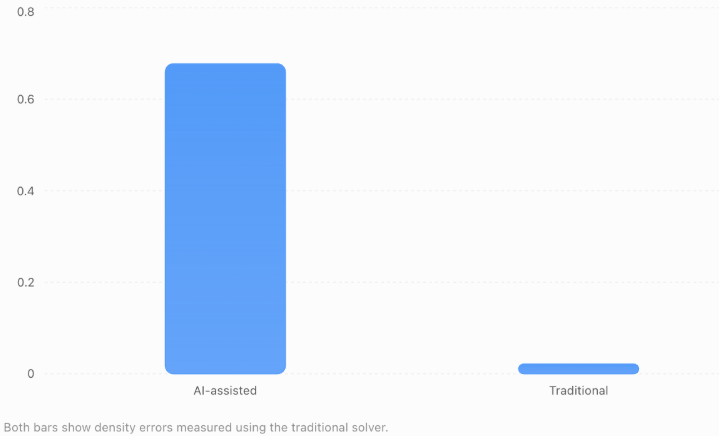



We compared traditional and AI-assisted optimization using the same objective, coefficient bounds, starting point, and optimizer settings. Both sets of selected controls were evaluated using the conventional GPE solver.
The verified density errors were similar: 0.253400 for traditional optimization and 0.254834 for AI-assisted optimization. However, the verified objective—including wave-function infidelity and a coefficient penalty—was lower for traditional optimization: 0.052612 compared with 0.122382.
The AI search took 0.21 seconds, compared with 121.88 seconds for traditional optimization. These times exclude neural-model training, data generation, and final verification. The AI also underestimated the objective of its selected controls, predicting 0.081621 instead of the verified 0.122382.
This experiment demonstrates fast surrogate-assisted search, but further accuracy improvements and controlled experiments are needed before recommending it for reliable control optimization

--------------------------------------------------------------------------------
This code plots the desired BEC target density alongside the results from traditional and AI-assisted optimization. It lets us visually compare how closely each method matches the target. It then displays the graph and saves it as optimal_control_comparison.png for the report.

Save our optimization comparison graph


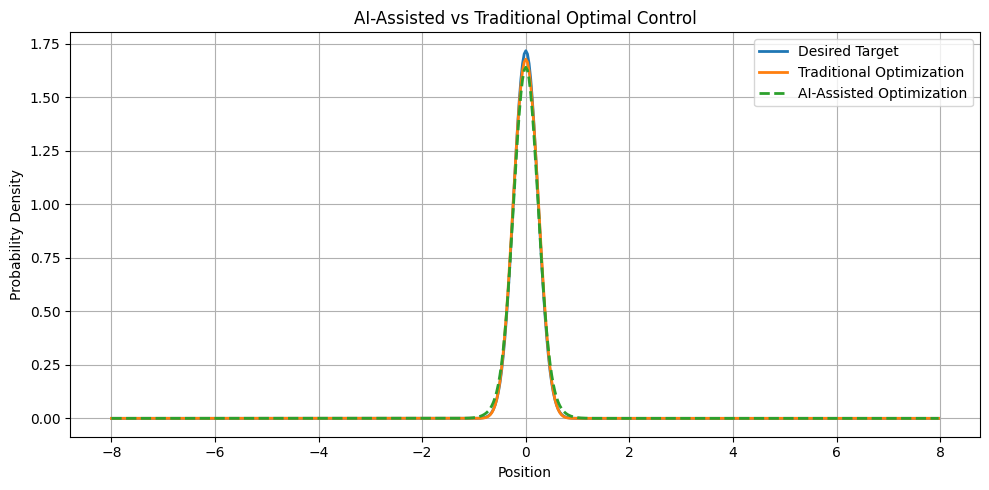

Optimization comparison graph saved successfully!


In [34]:
# @title
print("Save our optimization comparison graph")

# Compare AI-assisted and traditional optimal control

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    stable_target_density,
    label="Desired Target",
    linewidth=2
)

plt.plot(
    x,
    new_optimized_density,
    label="Traditional Optimization",
    linewidth=2
)

plt.plot(
    x,
    ai_verified_density,
    "--",
    label="AI-Assisted Optimization",
    linewidth=2
)

plt.xlabel("Position")
plt.ylabel("Probability Density")
plt.title("AI-Assisted vs Traditional Optimal Control")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "optimal_control_comparison.png",
    dpi=300
)

plt.show()

print("Optimization comparison graph saved successfully!")


--------------------------------------------------------------------------------
This code uses the saved simulation history to create a heatmap showing how the BEC’s probability density changes across position and time. Brighter colors indicate higher density. It displays the graph and saves it as P4c_spacetime_evolution.png.
This shows the traditional solver’s evolution, not the AI’s space-time prediction error.

Complete the space-time diagnostic
History shape: (101, 512)


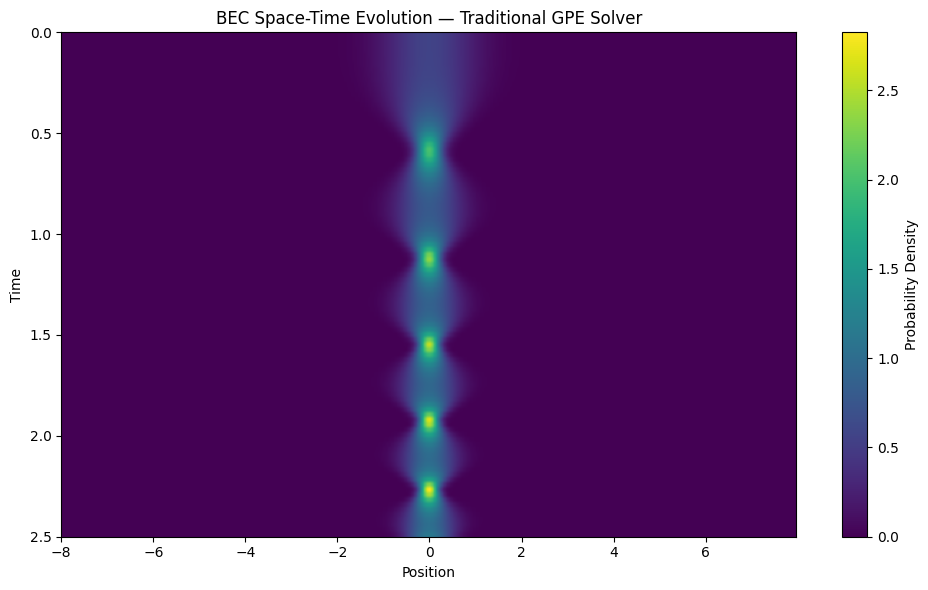

Space-time evolution graph saved successfully!


In [53]:
# @title
print("Complete the space-time diagnostic")

# Space-time evolution of the BEC using the traditional GPE solver

import numpy as np
import matplotlib.pyplot as plt

# Reuse the saved baseline simulation history
# history already contains probability densities |psi|^2
density_history = np.asarray(history)

print("History shape:", density_history.shape)

plt.figure(figsize=(10, 6))

plt.imshow(
    density_history,
    extent=[x[0], x[-1], times[-1], times[0]],
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Probability Density")
plt.xlabel("Position")
plt.ylabel("Time")
plt.title("BEC Space-Time Evolution — Traditional GPE Solver")

plt.tight_layout()
plt.savefig("P4c_spacetime_evolution.png", dpi=300)
plt.show()

print("Space-time evolution graph saved successfully!")


The heatmap shows the Bose–Einstein condensate becoming concentrated near the center as the trapping strength increases.
- Dark purple: Areas with very low probability density.
- Green and yellow: Areas with higher probability density.
- Bright spots near the center: Periods when the condensate becomes especially concentrated.
Notice that the bright spots appear repeatedly rather than forming one continuous bright line. This suggests the condensate undergoes oscillations as it is squeezed.
How to explain this in your presentation
We used a space-time heatmap to visualize how the Bose–Einstein condensate evolved under the traditional GPE solver. The simulation recorded 101 snapshots across 512 spatial positions. As the trapping strength increased, the condensate became more concentrated near the center, with visible oscillations during the process.

In [64]:
# @title Final Results and Computational Cost — P5

import numpy as np
import pandas as pd
import torch
import time
import platform

print("=" * 65)
print("FINAL RESULTS AND COMPUTATIONAL COST")
print("=" * 65)

# Hardware information
print("\nCOMPUTING ENVIRONMENT")
print("Operating system:", platform.system())
print("Processor:", platform.processor() or "Not reported")
print("PyTorch version:", torch.__version__)
print("PyTorch CPU threads:", torch.get_num_threads())
print("FNO device:", next(model.parameters()).device)
print("PINN device:", next(pinn_model.parameters()).device)

# Baseline verification
print("\nP1: CONVENTIONAL SOLVER VERIFICATION")
print(
    "Maximum time-refinement wave difference:",
    f"{baseline_verification['Time refinement wave difference (%)'].max():.6f}%"
)
print(
    "Maximum density difference against refined solve:",
    f"{baseline_verification['Density difference vs refined solve (%)'].max():.6f}%"
)

# Main PINN experiment
print("\nMAIN SPACE-TIME MODEL RESULTS")
space_time_summary = pd.DataFrame({
    "Model": ["Physics-informed", "Data only"],
    "Training wave error (%)": [
        100 * pinn_train_error,
        100 * data_only_train_error
    ],
    "Validation wave error (%)": [
        100 * np.mean(pinn_validation_errors),
        100 * np.mean(data_only_errors)
    ],
    "Training time (s)": [
        pinn_training_time,
        data_only_training_time
    ]
})
print(space_time_summary.round(4).to_string(index=False))

print(
    "\nSpace-time reference-data generation:",
    f"{trajectory_generation_time:.2f} seconds"
)

# Difficulty-sweep results include measured evaluation times
print("\nP3/P5: TIME-HORIZON EXPERIMENT")
print(horizon_results.round(4).to_string(index=False))

# Refresh FNO accuracy using the current trained model
model.eval()
parameter = next(model.parameters())

with torch.no_grad():
    current_test_predictions = model(
        test_x.to(
            device=parameter.device,
            dtype=parameter.dtype
        )
    ).cpu().numpy()

current_targets = test_y.detach().cpu().numpy()

current_fno_errors = (
    np.linalg.norm(
        (current_test_predictions - current_targets).reshape(
            len(current_targets), -1
        ),
        axis=1
    )
    / np.linalg.norm(
        current_targets.reshape(len(current_targets), -1),
        axis=1
    )
)

# Refresh single-query runtime
sample_controls = test_x[0].detach().cpu().numpy()

sample_tensor = test_x[0:1].to(
    device=parameter.device,
    dtype=parameter.dtype
)

def synchronize_model_device():
    if parameter.device.type == "cuda":
        torch.cuda.synchronize(parameter.device)

solver_measurements = []

for _ in range(5):
    start = time.perf_counter()
    simulate_smooth(sample_controls)
    solver_measurements.append(time.perf_counter() - start)

inference_measurements = []

with torch.no_grad():
    for _ in range(5):
        model(sample_tensor)

    synchronize_model_device()

    for _ in range(20):
        synchronize_model_device()
        start = time.perf_counter()

        model(sample_tensor)

        synchronize_model_device()
        inference_measurements.append(time.perf_counter() - start)

final_solver_time = float(np.mean(solver_measurements))
final_fno_time = float(np.mean(inference_measurements))

# Include original and additional dataset generation
final_fno_setup_time = (
    generation_time
    + extra_generation_time
    + experiment_results["100 examples"]["training_time"]
)

print("\nSUPPLEMENTARY FNO RESULTS")
print(
    "Mean exploratory final-time wave error:",
    f"{100 * current_fno_errors.mean():.2f}%"
)
print(f"Conventional final-time solve: {final_solver_time:.6f} s")
print(f"FNO prediction: {final_fno_time:.6f} s")
print(
    "Single-query inference speedup:",
    f"{final_solver_time / final_fno_time:.2f}x"
)
print(
    "FNO data generation plus 100-example training:",
    f"{final_fno_setup_time:.2f} s"
)

if final_solver_time > final_fno_time:
    final_break_even = int(np.ceil(
        final_fno_setup_time
        / (final_solver_time - final_fno_time)
    ))
    print("Timing-only break-even queries:", final_break_even)
else:
    final_break_even = None
    print("No timing break-even: FNO inference is not faster.")

print("\nINTERPRETATION")
print("Timing-only break-even does not establish useful accuracy.")
print("Setup cost excludes earlier development experiments.")
print("FNO errors describe final-time predictions.")
print("PINN errors describe complete space-time trajectories.")
print("Their error percentages are not directly interchangeable.")
print("No models were retrained or modified.")

space_time_summary.to_csv(
    "final_spacetime_results.csv", index=False
)

pd.DataFrame([{
    "FNO exploratory wave error (%)":
        100 * current_fno_errors.mean(),
    "Solver time (s)": final_solver_time,
    "FNO inference time (s)": final_fno_time,
    "FNO setup time (s)": final_fno_setup_time,
    "Timing-only break-even queries": final_break_even
}]).to_csv("final_FNO_cost_results.csv", index=False)

FINAL RESULTS AND COMPUTATIONAL COST

COMPUTING ENVIRONMENT
Operating system: Linux
Processor: x86_64
PyTorch version: 2.11.0+cpu
PyTorch CPU threads: 1
FNO device: cpu
PINN device: cpu

P1: CONVENTIONAL SOLVER VERIFICATION
Maximum time-refinement wave difference: 0.007970%
Maximum density difference against refined solve: 0.002591%

MAIN SPACE-TIME MODEL RESULTS
           Model  Training wave error (%)  Validation wave error (%)  Training time (s)
Physics-informed                  99.4451                    99.5413            10.9225
       Data only                  96.6369                    97.3898             1.0243

Space-time reference-data generation: 10.79 seconds

P3/P5: TIME-HORIZON EXPERIMENT
 Horizon         Approach  Validation wave error (%)  Mean predicted probability  Training time (s)  Five-trajectory evaluation time (s)
     0.1        Data only                     9.0913                      0.9720             2.9854                               0.0360
     0.1 Ph

Computational cost (P5)
Experiments ran on a Linux x86-64 CPU environment using PyTorch 2.11.0 with one CPU thread. The main PINN trained in 10.92 seconds; generating its reference trajectories took 10.79 seconds.
The supplementary FNO averaged 65.75% relative final-time wave error on five exploratory cases. Its measured inference speedup was approximately 768×, with a timing-only break-even estimate of 78 queries after including data generation and training. These timing benefits do not establish practical usefulness because prediction error remains substantial. Runtime measurements vary with the execution environment.

Conclusion and limitations
The conventional solver showed small differences under numerical refinement. In contrast, both space–time neural models struggled to fit the full trajectories and substantially underestimated total probability.
Shortening the time horizon improved accuracy. Physics-informed validation error increased from 10.81% at a horizon of 0.1 to 99.52% at 2.5. Data-only training also deteriorated, showing that physics losses alone do not explain the failure.
These results identify sensitivity to trajectory duration under a fixed training budget. They do not isolate representation, optimization, sampling, or temporal oscillations as the underlying cause. Conclusions are limited by one initialization, five validation controls, and the chosen architecture and loss weights.
We recommend retaining the conventional solver for reliable control evaluation. A useful next experiment would test time-window training against full-horizon training under matched computational budgets.